# Reproduksi — Application of MobileNetV2 to Waste Classification

**Paper.** Yong, L., Ma, L., Sun, D., & Du, L. (2023). *Application of MobileNetV2 to waste classification.*
PLOS ONE, 18(3), e0282336. <https://doi.org/10.1371/journal.pone.0282336> | `Paper/journal.pone.0282336.pdf`

**Kode sumber asli.** `Source Code/` (`train_245_class.py`, `train_cnn.py`, `train_mobilenet.py`,
`test_model.py`, `utils.py`, `main.py`).

Notebook ini menulis ulang pipeline paper menjadi satu notebook yang dapat dijalankan. Dataset yang
dipakai adalah **Kaggle “Recyclable and Household Waste Classification”** (Alistair King, 2024),
bukan dataset 245 kelas milik paper. Dataset dideteksi otomatis di Kaggle, diunduh otomatis di Colab,
dan dibaca dari `Datasets/` saat dijalankan secara lokal.

> **Pemilihan data.** Dataset menyediakan dua kelompok gambar, `default` dan `real_world`.
> Keduanya dipakai. Karena banyak file identik — baik antar-kelompok maupun antar-kelas — notebook
> menghapus duplikat exact berdasarkan MD5 sebelum split. Pada dataset ini tersisa 11.263 gambar
> unik dari 15.000 file, dengan 264–491 gambar per kelas.

---

## Yang direproduksi

| Elemen paper | Notebook ini |
|---|---|
| Dataset 245 kelas, split 8:1:1 | Dataset Kaggle 30 kelas, split 8:1:1 stratified |
| Transfer learning MobileNetV2, 50 epoch | MobileNetV2 `torchvision` (PyTorch), 50 epoch |
| SGD, lr 0.001, momentum 0.9, StepLR (7, 0.1) | Optimizer dan scheduler sama |
| RandomResizedCrop(224), flip, normalisasi ImageNet | Transform training sama |
| Resize(256) + CenterCrop(224) untuk validasi/test | Transform evaluasi sama |
| Cross-entropy loss, accuracy, laporan per kelas | Accuracy, loss, dan classification report 3 superclass; metrik lain sebagai insight |
| CNN klasik sebagai pembanding, 30 epoch | Arsitektur sama, diimplementasikan ulang di PyTorch, 30 epoch |
| Aplikasi | Tidak diimplementasikan |

## Perbedaan penting

1. **30 kelas, bukan 245.** Dataset Kaggle memiliki 30 kelas. Setelah deduplikasi, jumlah gambar
   per kelas tidak seragam (264–491) dengan total 11.263 gambar unik. Output model karena itu 30
   kelas, bukan 245.
2. **Tiga kategori besar, bukan empat.** Paper memakai recyclable, kitchen, hazardous, dan other.
   Dataset ini **tidak memiliki kelas hazardous**, sehingga evaluasi superclass hanya mencakup
   **Kitchen waste**, **Recyclable waste**, dan **Other waste**. Mapping ditulis eksplisit di Bagian 2.
3. **Hanya PyTorch.** Repositori asli mencampur PyTorch (`train_245_class.py`, `main.py`) dan
   TensorFlow/Keras (`train_cnn.py`, `train_mobilenet.py`). Notebook ini memakai PyTorch di seluruh
   bagian agar kedua model memakai manifest, split, dan loop training yang sama; preprocessing tetap
   mengikuti model masing-masing. CNN baseline tetap mempertahankan arsitektur paper
   (Conv 32 → pool → Conv 64 → pool → Dense 128 → softmax).
4. **Angka absolut akan berbeda.** Paper melaporkan 82,92% MobileNetV2 dan 67,5% CNN pada dataset
   245 kelas miliknya. Dengan 30 kelas yang lebih mudah dan split yang berbeda, hasilnya pasti
   berbeda. Tujuan notebook ini adalah mereproduksi **metode** dan menghasilkan perbandingan yang
   valid pada dataset pengganti.
5. **Aplikasi tidak diimplementasikan.** Fokus reproduksi ada di computer vision.

## Perilaku per platform

| Lingkungan | Sumber data |
|---|---|
| **Kaggle** | Memakai dataset terlampir di `/kaggle/input/recyclable-and-household-waste-classification/...` |
| **Google Colab** | Mengunduh `alistairking/recyclable-and-household-waste-classification` dengan `kagglehub` |
| **Lokal** | Memakai `Datasets/images/images/` (atau path dari `TRASH_DATA_DIR`) |

Jalankan semua cell dari atas ke bawah. Cell training berjalan lama; ada switch `QUICK_TEST` untuk
smoke test cepat.


## Daftar isi

1. Setup dan konfigurasi
2. Pencarian dataset (Kaggle / Colab / lokal)
3. Exploratory data analysis
4. Split 8:1:1 stratified
5. Dataset, transform, dan loader
6. Model MobileNetV2
7. Training loop
8. Training MobileNetV2 (50 epoch)
9. Kurva training
10. Evaluasi test: 30 kelas dan 3 superclass
11. Confusion matrix
12. Inference tiga gambar
13. CNN baseline (30 epoch)
14. Analisis kesalahan testing
15. Perbandingan model
16. Simpan ringkasan

## 1. Setup dan konfigurasi

Cell pertama di bagian ini otomatis memasang library yang belum ada (pip install) sehingga notebook
dapat langsung dijalankan di Jupyter lokal, Kaggle, maupun Colab tanpa persiapan manual.

Cell berikutnya mengimpor library, menetapkan random seed, mendefinisikan folder output, dan menulis
hyperparameter utama. Nilainya mengikuti `train_245_class.py` kecuali disebutkan lain.

Jika `QUICK_TEST` aktif (environment variable `TRASH_REPRO_QUICK=1`), notebook hanya training satu
epoch pada subset kecil yang stratified.


In [1]:
# ---------------------------------------------------------------------------
# Auto-install dependencies.
#
# This cell runs before the main imports, so a fresh environment (local
# Jupyter, Kaggle, Colab) can run the notebook without manual setup.
# Packages that are already installed are never touched.
# ---------------------------------------------------------------------------
from __future__ import annotations

import importlib.util
import subprocess
import sys


def module_available(name: str) -> bool:
    """True when the module can be imported without importing it."""
    return importlib.util.find_spec(name) is not None


def pip_install(*packages: str, index_url: str | None = None) -> bool:
    """Install packages quietly with pip. Returns True on a successful run."""
    command = [sys.executable, "-m", "pip", "install", "-q"]
    if index_url:
        command += ["--index-url", index_url]
    command += list(packages)

    print("    $", " ".join(command))
    try:
        result = subprocess.run(command, check=False)
        return result.returncode == 0
    except Exception as exc:  # pragma: no cover - network or permission issues
        print(f"[warn] pip install failed for {' '.join(packages)}: {exc}")
        return False


def ensure(packages: dict[str, str]) -> list[str]:
    """Install every package whose import name is missing.

    ``packages`` maps the pip name to the import name.
    Returns the list of packages that are still missing afterwards.
    """
    missing = [pkg for pkg, mod in packages.items() if not module_available(mod)]
    if not missing:
        return []

    print(f"[setup] installing: {', '.join(missing)}")
    for package in missing:
        pip_install(package)

    still_missing = [pkg for pkg in missing if not module_available(packages[pkg])]
    if still_missing:
        print(
            "[warn] could not install: "
            + ", ".join(still_missing)
            + "\n[warn] install them manually with: "
            + "pip install -r requirements.txt"
        )
    return still_missing


LIGHT_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "Pillow": "PIL",
    "tqdm": "tqdm",
    # ipywidgets powers the interactive progress bar of tqdm inside Jupyter.
    "ipywidgets": "ipywidgets",
}

ensure(LIGHT_PACKAGES)

# PyTorch is the heavy dependency. Kaggle and Colab images already ship a
# CUDA build, so it is only installed when it is really absent. The CPU
# wheel is used first because it is far smaller than the CUDA bundle.
if not module_available("torch") or not module_available("torchvision"):
    print("[setup] installing torch and torchvision")
    installed = pip_install(
        "torch",
        "torchvision",
        index_url="https://download.pytorch.org/whl/cpu",
    )
    if not installed and (not module_available("torch") or not module_available("torchvision")):
        print("[setup] retrying with the default PyPI index")
        pip_install("torch", "torchvision")

# kagglehub is only needed for the automatic Kaggle download in Colab.
if not module_available("kagglehub"):
    pip_install("kagglehub")

print("[setup] dependency check done")


[setup] dependency check done


In [2]:
from __future__ import annotations

import copy
import hashlib
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from collections import Counter, deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
# Progress bar. The interactive notebook widget is used when IProgress is
# available so the bar stays live; otherwise the plain console version is used.
try:
    from ipywidgets import IProgress  # noqa: F401
    from tqdm.auto import tqdm
except Exception:
    from tqdm import tqdm
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.unicode_minus": False,
    "figure.autolayout": False,
})

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()

# ---------------------------------------------------------------------------
# Runtime detection
# ---------------------------------------------------------------------------
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

IN_KAGGLE = Path("/kaggle/input").exists() or os.environ.get("KAGGLE_KERNEL_RUN_TYPE") is not None

# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()
OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
SPLIT_DIR = OUTPUT_DIR / "splits"
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
for _d in (OUTPUT_DIR, SPLIT_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# Dataset source
# ---------------------------------------------------------------------------
KAGGLE_DATASET_SLUG = "alistairking/recyclable-and-household-waste-classification"
KAGGLE_DATASET_URL = (
    "https://www.kaggle.com/datasets/alistairking/"
    "recyclable-and-household-waste-classification"
)
LOCAL_DATA_DIR = os.environ.get("TRASH_DATA_DIR", "").strip()
ALLOW_KAGGLE_DOWNLOAD = True

# The dataset ships images in `default` and `real_world`; exact duplicates occur
# both across groups and across classes. Both groups are kept, and duplicates
# are removed by MD5 before the split (see Section 3).

# ---------------------------------------------------------------------------
# Training hyperparameters (paper defaults from train_245_class.py)
# ---------------------------------------------------------------------------
IMG_SIZE = 224
BATCH_SIZE = 42
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
MOMENTUM = 0.9
STEP_SIZE = 7
GAMMA = 0.1
NUM_WORKERS = 0
PRETRAINED = os.environ.get("TRASH_REPRO_PRETRAINED", "1") == "1"

# Classic CNN baseline (paper: train_cnn.py, Adam, batch 16, 30 epochs)
CNN_BATCH_SIZE = 16
CNN_EPOCHS = 30
CNN_LEARNING_RATE = 1e-3

# Test loader uses a larger batch, matching test_model.py (batch 128).
TEST_BATCH_SIZE = 128

# Optional switch for a fast single-epoch run on a small subset.
QUICK_TEST = os.environ.get("TRASH_REPRO_QUICK", "0") == "1"
TRAIN_PER_CLASS = VAL_PER_CLASS = TEST_PER_CLASS = None
if QUICK_TEST:
    NUM_EPOCHS = 1
    CNN_EPOCHS = 1
    BATCH_SIZE = 16
    CNN_BATCH_SIZE = 16
    NUM_WORKERS = 0
    PRETRAINED = False
    TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 20, 5, 5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python           : {sys.version.split()[0]}")
print(f"PyTorch          : {torch.__version__}")
print(f"Device           : {DEVICE}")
print(f"Platform         : {'Kaggle' if IN_KAGGLE else ('Colab' if IN_COLAB else 'Local')}")
print(f"Notebook folder  : {NOTEBOOK_DIR}")
print(f"Output folder    : {OUTPUT_DIR}")
print(f"Quick test       : {QUICK_TEST}")
print(f"Pretrained weights: {PRETRAINED}")

Python           : 3.12.3
PyTorch          : 2.15.0+cu132
Device           : cuda
Platform         : Local
Notebook folder  : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16
Output folder    : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs
Quick test       : False
Pretrained weights: True


In [3]:
# ---------------------------------------------------------------------------
# Final dependency verification. Anything still missing is reported with the
# exact command needed to fix it.
# ---------------------------------------------------------------------------
missing = []
for module_name, import_name in [
    ("numpy", "numpy"), ("pandas", "pandas"), ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"), ("sklearn", "sklearn"), ("PIL", "PIL"), ("tqdm", "tqdm"),
]:
    if not module_available(import_name):
        missing.append(module_name)

if missing:
    print("Installing missing packages:", missing)
    ensure({
        "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
        "seaborn": "seaborn", "scikit-learn": "sklearn", "Pillow": "PIL",
        "tqdm": "tqdm",
    })

if not module_available("torch") or not module_available("torchvision"):
    raise ImportError(
        "PyTorch and torchvision are required. On Colab/Kaggle they are preinstalled. "
        "Install them with: pip install torch torchvision"
    )

print("Core dependencies are available.")


Core dependencies are available.


## 2. Pencarian dataset

Struktur dataset:

```text
recyclable-and-household-waste-classification/
└── images/
    └── images/
        ├── aerosol_cans/
        │   ├── default/*.png
        │   └── real_world/*.png
        ├── aluminum_food_cans/
        ...
        └── tea_bags/
```

Resolver di bawah mencari folder yang berisi langsung 30 folder kelas. Urutan pengecekan:

1. `TRASH_DATA_DIR`, jika diatur;
2. path platform umum (`/kaggle/input/...`, `Datasets/images/images`, ...);
3. di Colab, unduhan `kagglehub` dari dataset publik;
4. fallback CLI `kaggle` / URL langsung.

Daftar 30 kelas dan mapping superclass ditulis eksplisit agar sisa notebook tidak bergantung pada
struktur folder. Kedua source group, `default` dan `real_world`, tetap dipakai; duplikat exact
dihapus pada Bagian 3 sebelum split.


In [4]:
# ---------------------------------------------------------------------------
# Class list (exactly the 30 folders in the Kaggle dataset)
# ---------------------------------------------------------------------------
CLASS_NAMES = [
    "aerosol_cans",
    "aluminum_food_cans",
    "aluminum_soda_cans",
    "cardboard_boxes",
    "cardboard_packaging",
    "clothing",
    "coffee_grounds",
    "disposable_plastic_cutlery",
    "eggshells",
    "food_waste",
    "glass_beverage_bottles",
    "glass_cosmetic_containers",
    "glass_food_jars",
    "magazines",
    "newspaper",
    "office_paper",
    "paper_cups",
    "plastic_cup_lids",
    "plastic_detergent_bottles",
    "plastic_food_containers",
    "plastic_shopping_bags",
    "plastic_soda_bottles",
    "plastic_straws",
    "plastic_trash_bags",
    "plastic_water_bottles",
    "shoes",
    "steel_food_cans",
    "styrofoam_cups",
    "styrofoam_food_containers",
    "tea_bags",
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

# ---------------------------------------------------------------------------
# Superclass mapping. The Kaggle dataset has no hazardous-waste class, so the
# paper's fourth superclass cannot be evaluated. Edit this dict if another
# superclass convention is required.
# ---------------------------------------------------------------------------
MAJOR_NAMES = ["Kitchen waste", "Recyclable waste", "Other waste"]
MAJOR_TO_IDX = {name: i for i, name in enumerate(MAJOR_NAMES)}

CLASS_TO_MAJOR = {
    # Kitchen / organic
    "coffee_grounds": "Kitchen waste",
    "eggshells": "Kitchen waste",
    "food_waste": "Kitchen waste",
    "tea_bags": "Kitchen waste",
    # Recyclable
    "aerosol_cans": "Recyclable waste",
    "aluminum_food_cans": "Recyclable waste",
    "aluminum_soda_cans": "Recyclable waste",
    "cardboard_boxes": "Recyclable waste",
    "cardboard_packaging": "Recyclable waste",
    "clothing": "Recyclable waste",
    "glass_beverage_bottles": "Recyclable waste",
    "glass_cosmetic_containers": "Recyclable waste",
    "glass_food_jars": "Recyclable waste",
    "magazines": "Recyclable waste",
    "newspaper": "Recyclable waste",
    "office_paper": "Recyclable waste",
    "paper_cups": "Recyclable waste",
    "plastic_detergent_bottles": "Recyclable waste",
    "plastic_food_containers": "Recyclable waste",
    "plastic_shopping_bags": "Recyclable waste",
    "plastic_soda_bottles": "Recyclable waste",
    "plastic_water_bottles": "Recyclable waste",
    "shoes": "Recyclable waste",
    "steel_food_cans": "Recyclable waste",
    # Other / non-recyclable
    "disposable_plastic_cutlery": "Other waste",
    "plastic_cup_lids": "Other waste",
    "plastic_straws": "Other waste",
    "plastic_trash_bags": "Other waste",
    "styrofoam_cups": "Other waste",
    "styrofoam_food_containers": "Other waste",
}

missing_mapping = sorted(set(CLASS_NAMES) - set(CLASS_TO_MAJOR))
assert not missing_mapping, f"Missing superclass mapping for: {missing_mapping}"

print(f"Classes: {NUM_CLASSES}")
print(f"Superclasses: {MAJOR_NAMES}")
print(pd.Series(CLASS_TO_MAJOR).value_counts().to_string())

Classes: 30
Superclasses: ['Kitchen waste', 'Recyclable waste', 'Other waste']
Recyclable waste    20
Other waste          6
Kitchen waste        4


In [5]:
# ---------------------------------------------------------------------------
# Dataset locator
# ---------------------------------------------------------------------------
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
EXPECTED_CLASS_SET = set(CLASS_NAMES)


def is_class_root(path: Path) -> bool:
    '''True when *path* directly contains every expected class directory.'''
    try:
        names = {p.name for p in path.iterdir() if p.is_dir()}
    except (OSError, PermissionError):
        return False
    return EXPECTED_CLASS_SET.issubset(names)


def find_class_root(base, max_depth: int = 6, max_dirs: int = 50000):
    '''Breadth-first search for the directory that contains all class folders.'''
    base = Path(base).expanduser()
    if not base.exists():
        return None
    if is_class_root(base):
        return base

    queue = deque([(base, 0)])
    visited = 0
    skip = {"__MACOSX", ".git", "node_modules", ".ipynb_checkpoints", "Source Code", "Reproduce Code"}
    while queue:
        current, depth = queue.popleft()
        if depth >= max_depth:
            continue
        try:
            children = [
                p for p in current.iterdir()
                if p.is_dir() and not p.name.startswith(".") and p.name not in skip
            ]
        except (OSError, PermissionError):
            continue
        for child in children:
            visited += 1
            if visited > max_dirs:
                return None
            if is_class_root(child):
                return child
            queue.append((child, depth + 1))
    return None


def platform_candidates():
    cwd = Path.cwd()
    candidates = []
    if LOCAL_DATA_DIR:
        candidates.append(Path(LOCAL_DATA_DIR))

    # Local / repository layout
    candidates += [
        cwd / "Datasets" / "images" / "images",
        cwd / "Datasets" / "images",
        cwd.parent / "Datasets" / "images" / "images",
        cwd.parent / "Datasets" / "images",
        cwd.parent.parent / "Datasets" / "images" / "images",
        Path("/content/Datasets/images/images"),
        Path("/content/datasets/images/images"),
    ]

    # Kaggle input layout
    candidates += [
        Path("/kaggle/input/recyclable-and-household-waste-classification/images/images"),
        Path("/kaggle/input/recyclable-and-household-waste-classification/images"),
        Path("/kaggle/input/recyclable-and-household-waste-classification"),
    ]

    # Any other attached Kaggle dataset with the same images folder
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        try:
            for child in sorted(kaggle_input.iterdir()):
                if child.is_dir():
                    candidates += [child / "images" / "images", child / "images", child]
        except OSError:
            pass

    # Colab download destinations
    candidates += [
        Path("/content/kaggle_dataset"),
        Path("/content/recyclable-and-household-waste-classification"),
        Path.home() / ".cache" / "kagglehub" / "datasets" / "alistairking" /
        "recyclable-and-household-waste-classification",
    ]
    # De-duplicate while preserving order
    seen, unique = set(), []
    for p in candidates:
        key = str(p)
        if key not in seen:
            seen.add(key)
            unique.append(p)
    return unique


def locate_local_dataset():
    for candidate in platform_candidates():
        root = find_class_root(candidate, max_depth=6)
        if root is not None:
            print(f"Found dataset at: {root}")
            return root
    return None


def extract_zip(zip_path: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(destination)
    print(f"Extracted {zip_path.name} -> {destination}")


def download_kaggle_dataset():
    '''Download the public Kaggle dataset on Colab. Tries kagglehub, CLI, then URL.'''
    destination = Path("/content/kaggle_dataset")
    destination.mkdir(parents=True, exist_ok=True)

    # Optional Colab secrets (only needed if Kaggle asks for consent/authentication).
    if IN_COLAB:
        try:
            from google.colab import userdata
            for secret in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
                try:
                    value = userdata.get(secret)
                except Exception:
                    value = None
                if value:
                    os.environ[secret] = value
        except Exception:
            pass

    # 1) kagglehub
    try:
        import kagglehub
        print("Downloading with kagglehub ...")
        downloaded = kagglehub.dataset_download(KAGGLE_DATASET_SLUG)
        print(f"kagglehub returned: {downloaded}")
        downloaded = Path(downloaded)
        if downloaded.is_file() and downloaded.suffix.lower() == ".zip":
            extract_zip(downloaded, destination)
            downloaded = destination
        root = find_class_root(downloaded, max_depth=6)
        if root is not None:
            return root
    except Exception as exc:
        print(f"kagglehub download failed: {exc}")

    # 2) kaggle CLI
    try:
        if shutil.which("kaggle") is None:
            subprocess.run(
                [sys.executable, "-m", "pip", "install", "-q", "kaggle"],
                check=False,
            )
        if shutil.which("kaggle") is not None:
            print("Downloading with kaggle CLI ...")
            subprocess.run(
                [
                    "kaggle", "datasets", "download",
                    "-d", KAGGLE_DATASET_SLUG,
                    "-p", str(destination),
                    "--unzip",
                ],
                check=False,
            )
            root = find_class_root(destination, max_depth=6)
            if root is not None:
                return root
    except Exception as exc:
        print(f"kaggle CLI download failed: {exc}")

    # 3) Direct API URL (works only when the dataset needs no authentication)
    try:
        import urllib.request
        zip_path = destination / "dataset.zip"
        url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET_SLUG}"
        print("Trying direct Kaggle API download ...")
        urllib.request.urlretrieve(url, zip_path)
        extract_zip(zip_path, destination)
        root = find_class_root(destination, max_depth=6)
        if root is not None:
            return root
    except Exception as exc:
        print(f"Direct download failed: {exc}")

    return None


DATA_ROOT = locate_local_dataset()
if DATA_ROOT is None and IN_COLAB and ALLOW_KAGGLE_DOWNLOAD:
    DATA_ROOT = download_kaggle_dataset()

if DATA_ROOT is None:
    extra = ""
    if IN_KAGGLE:
        extra = (
            "\\nOn Kaggle, use **Add Data** and attach "
            "`alistairking/recyclable-and-household-waste-classification`, then rerun this cell."
        )
    elif IN_COLAB:
        extra = (
            "\\nOn Colab, check that the dataset is public and, if Kaggle requests it, "
            "add a `KAGGLE_API_TOKEN` secret in the Colab key panel."
        )
    else:
        extra = "\\nSet `TRASH_DATA_DIR` to the folder that contains the 30 class directories."
    raise FileNotFoundError(
        "Could not find the 30 class folders. "
        f"Dataset: {KAGGLE_DATASET_URL}{extra}"
    )

DATA_ROOT = Path(DATA_ROOT).resolve()
print("\\nUsing DATA_ROOT:")
print(DATA_ROOT)
print("\\nTop-level entries:", sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir())[:5], "...")

Found dataset at: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/Datasets/images/images
\nUsing DATA_ROOT:
/mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/Datasets/images/images
\nTop-level entries: ['aerosol_cans', 'aluminum_food_cans', 'aluminum_soda_cans', 'cardboard_boxes', 'cardboard_packaging'] ...


## 3. Exploratory data analysis

Membuat manifest seluruh gambar `default` dan `real_world`, memeriksa jumlah per kelas, dan
menampilkan beberapa contoh. Kolom `source_group` disimpan sebagai metadata asal gambar. Duplikat
exact dihapus berdasarkan MD5, sehingga satu gambar tidak bisa muncul di dua split meskipun file-nya
berada di kelas atau source group yang berbeda.


Checking images:   0%|                                                                                                                                          | 0/15000 [00:00<?, ?it/s]

Checking images:   5%|██████▊                                                                                                                       | 812/15000 [00:00<00:01, 8115.40it/s]

Checking images:  13%|███████████████▊                                                                                                             | 1902/15000 [00:00<00:01, 9748.36it/s]

Checking images:  19%|████████████████████████                                                                                                     | 2893/15000 [00:00<00:01, 9820.08it/s]

Checking images:  26%|████████████████████████████████▎                                                                                            | 3876/15000 [00:00<00:01, 8902.97it/s]

...

Hashing images: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15000/15000 [00:02<00:00, 6640.72it/s]

Removed 3,737 exact duplicate image(s); 11,263 unique images remain.
Images: 11,263


source_group,default,real_world
class_name,,
aerosol_cans,239,114
aluminum_food_cans,243,139
aluminum_soda_cans,236,145
cardboard_boxes,242,156
cardboard_packaging,144,121
clothing,249,242
coffee_grounds,242,125
disposable_plastic_cutlery,247,114
eggshells,247,159


Class totals:


class_name,aerosol_cans,aluminum_food_cans,aluminum_soda_cans,cardboard_boxes,cardboard_packaging,clothing,coffee_grounds,disposable_plastic_cutlery,eggshells,food_waste,...,plastic_shopping_bags,plastic_soda_bottles,plastic_straws,plastic_trash_bags,plastic_water_bottles,shoes,steel_food_cans,styrofoam_cups,styrofoam_food_containers,tea_bags
images,353,382,381,398,265,491,367,361,406,299,...,373,342,404,362,383,487,264,362,334,396


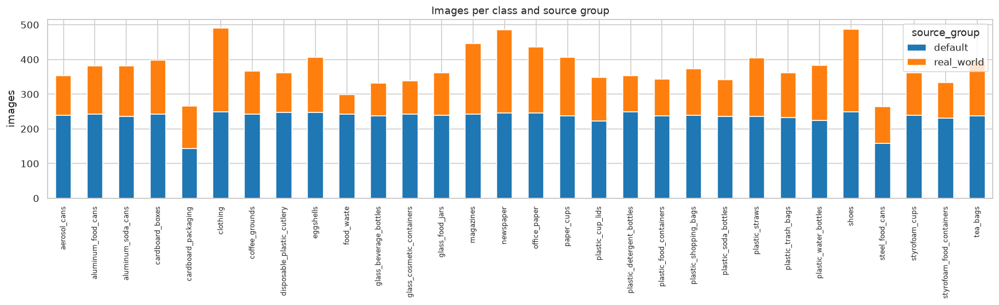

In [6]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATA_ROOT / class_name
    if not class_dir.exists():
        raise FileNotFoundError(f"Missing class folder: {class_dir}")
    for path in sorted(class_dir.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        parts = path.relative_to(DATA_ROOT).parts
        source_group = next((p for p in parts if p in {"default", "real_world"}), "unknown")
        records.append({
            "abs_path": str(path),
            "rel_path": path.relative_to(DATA_ROOT).as_posix(),
            "class_name": class_name,
            "source_group": source_group,
        })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError(f"No images found under {DATA_ROOT}")

available_groups = sorted(df["source_group"].unique())
missing_groups = sorted({"default", "real_world"} - set(available_groups))
if missing_groups:
    raise RuntimeError(
        f"Missing source groups: {missing_groups}. Found: {available_groups}"
    )

# Optional integrity check. In quick mode only a sample is checked to keep startup fast.
VALIDATE_IMAGES = True
if VALIDATE_IMAGES:
    check_paths = (
        df["abs_path"].sample(min(len(df), 300), random_state=SEED)
        if QUICK_TEST else df["abs_path"]
    )
    bad_paths = []
    for path in tqdm(check_paths, desc="Checking images"):
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            bad_paths.append(path)
    if bad_paths:
        print(f"Dropping {len(bad_paths)} unreadable image(s).")
        df = df[~df["abs_path"].isin(bad_paths)].reset_index(drop=True)

# Remove exact duplicates across both source groups and across classes. Keeping
# one copy per MD5 prevents the same image from landing in different splits.
df["md5"] = [
    hashlib.md5(Path(path).read_bytes()).hexdigest()
    for path in tqdm(df["abs_path"], desc="Hashing images")
]
before_dedup = len(df)
df = (
    df.sort_values("rel_path")
    .drop_duplicates("md5", keep="first")
    .reset_index(drop=True)
)
duplicates_removed = before_dedup - len(df)
print(
    f"Removed {duplicates_removed:,} exact duplicate image(s); "
    f"{len(df):,} unique images remain."
)

missing_classes = sorted(set(CLASS_NAMES) - set(df["class_name"]))
if missing_classes:
    raise RuntimeError(f"No images for: {missing_classes}")

missing_groups = sorted({"default", "real_world"} - set(df["source_group"].unique()))
if missing_groups:
    raise RuntimeError(f"Source groups lost after deduplication: {missing_groups}")

print(f"Images: {len(df):,}")
counts = df.groupby(["class_name", "source_group"]).size().unstack(fill_value=0)
counts = counts.reindex(CLASS_NAMES)
display(counts)
print("Class totals:")
display(counts.sum(axis=1).rename("images").to_frame().T)

fig, ax = plt.subplots(figsize=(16, 5))
counts.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=sns.color_palette("tab10", n_colors=len(counts.columns)),
)
ax.set_title("Images per class and source group")
ax.set_xlabel("")
ax.set_ylabel("images")
ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)


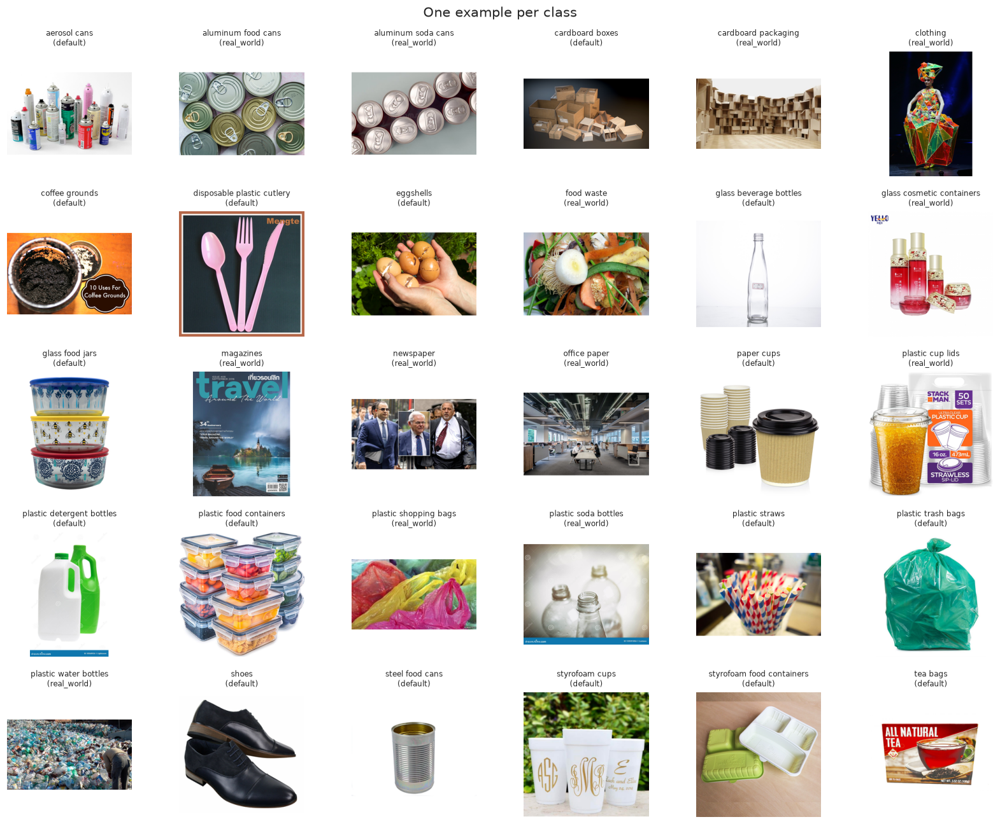

Most common image sizes (width, height):
  (256, 256): 500


In [7]:
# One sample per class; the source group is shown in the title.
fig, axes = plt.subplots(5, 6, figsize=(15, 12))
for ax, class_name in zip(axes.ravel(), CLASS_NAMES):
    subset = df[df["class_name"] == class_name]
    row = subset.sample(1, random_state=SEED).iloc[0]
    with Image.open(row["abs_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(
        f"{class_name.replace('_', ' ')}\n({row['source_group']})",
        fontsize=8,
    )
    ax.axis("off")
fig.suptitle("One example per class", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_samples.png", bbox_inches="tight")
plt.show()
plt.close(fig)

sizes = Counter()
for path in df["abs_path"].sample(min(len(df), 500), random_state=SEED):
    with Image.open(path) as img:
        sizes[img.size] += 1
print("Most common image sizes (width, height):")
for size, n in sizes.most_common(8):
    print(f"  {size}: {n}")


### Ringkasan tambahan

Bagian ini melengkapi EDA dengan statistik keseimbangan kelas, komposisi source group, ukuran
gambar, dan kecerahan. Tujuannya memeriksa apakah distribusi data cukup seragam sebelum split.

,Value
files before dedupe,15000.00
unique images,11263.00
duplicates removed,3737.00
unique md5,11263.00
classes,30.00
min images per class,264.00
max images per class,491.00
mean images per class,375.43
median images per class,364.50
max/min ratio,1.86


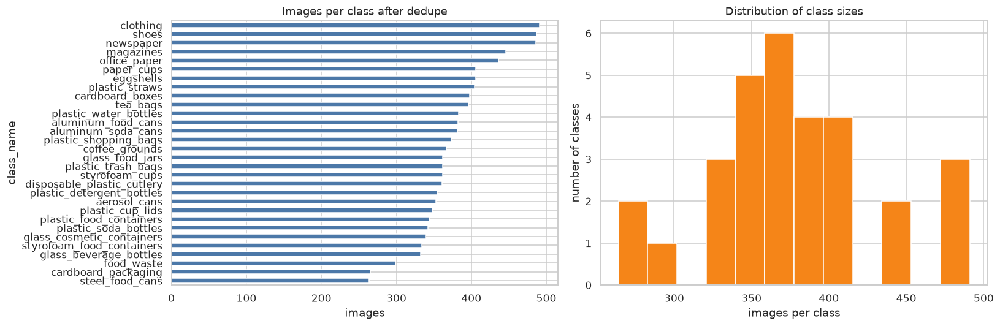

In [8]:
class_counts = df.groupby("class_name").size()
source_counts = df.groupby("source_group").size()
total_files = len(df) + int(duplicates_removed)

eda_summary = pd.DataFrame({
    "Value": [
        total_files,
        len(df),
        int(duplicates_removed),
        df["md5"].nunique(),
        df["class_name"].nunique(),
        int(class_counts.min()),
        int(class_counts.max()),
        round(float(class_counts.mean()), 2),
        float(class_counts.median()),
        round(float(class_counts.max() / class_counts.min()), 2),
        int(source_counts.get("default", 0)),
        int(source_counts.get("real_world", 0)),
    ],
}, index=[
    "files before dedupe",
    "unique images",
    "duplicates removed",
    "unique md5",
    "classes",
    "min images per class",
    "max images per class",
    "mean images per class",
    "median images per class",
    "max/min ratio",
    "default images",
    "real_world images",
])
display(eda_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
class_counts.sort_values().plot(kind="barh", ax=axes[0], color="#4C78A8")
axes[0].set_title("Images per class after dedupe")
axes[0].set_xlabel("images")
axes[1].hist(class_counts.values, bins=12, color="#F58518", edgecolor="white")
axes[1].set_title("Distribution of class sizes")
axes[1].set_xlabel("images per class")
axes[1].set_ylabel("number of classes")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_class_balance.png", bbox_inches="tight")
plt.show()
plt.close(fig)

,width,height,aspect_ratio,brightness,contrast
count,800.0,800.0,800.0,800.00,800.00
mean,256.0,256.0,1.0,185.99,62.01
std,0.0,0.0,0.0,37.95,21.95
min,256.0,256.0,1.0,42.18,6.45
25%,256.0,256.0,1.0,162.82,47.37
50%,256.0,256.0,1.0,190.39,62.06
75%,256.0,256.0,1.0,214.92,78.12
max,256.0,256.0,1.0,248.65,119.87


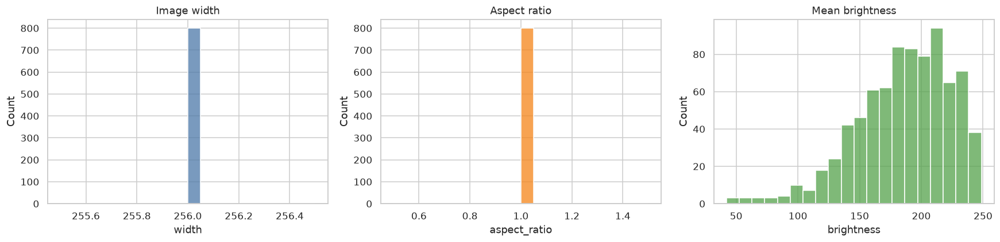

Mean brightness/contrast per class (sample):


,brightness,contrast
class_name,,
aerosol_cans,186.77,68.38
aluminum_food_cans,195.26,57.83
aluminum_soda_cans,185.97,62.60
cardboard_boxes,204.79,57.46
cardboard_packaging,197.98,51.23
clothing,173.67,73.20
coffee_grounds,141.46,83.32
disposable_plastic_cutlery,178.68,47.03
eggshells,183.03,65.66


In [9]:
eda_sample = df.sample(min(len(df), 800), random_state=SEED)
image_stats = []
for row in eda_sample.itertuples():
    with Image.open(row.abs_path) as img:
        rgb = img.convert("RGB")
        width, height = rgb.size
        gray = np.asarray(rgb.convert("L").resize((64, 64)), dtype=np.float32)
    image_stats.append({
        "class_name": row.class_name,
        "width": width,
        "height": height,
        "aspect_ratio": width / height,
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
    })
image_stats = pd.DataFrame(image_stats)
display(image_stats[["width", "height", "aspect_ratio", "brightness", "contrast"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(image_stats["width"], bins=20, ax=axes[0], color="#4C78A8")
axes[0].set_title("Image width")
sns.histplot(image_stats["aspect_ratio"], bins=20, ax=axes[1], color="#F58518")
axes[1].set_title("Aspect ratio")
sns.histplot(image_stats["brightness"], bins=20, ax=axes[2], color="#54A24B")
axes[2].set_title("Mean brightness")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eda_image_stats.png", bbox_inches="tight")
plt.show()
plt.close(fig)

class_image_stats = (
    image_stats.groupby("class_name")[["brightness", "contrast"]]
    .mean()
    .round(2)
)
print("Mean brightness/contrast per class (sample):")
display(class_image_stats)

## 4. Split 8:1:1 stratified

Bagian ini menggantikan `utils.py:data_set_split`. Alih-alih menyalin file ke folder `train/val/test`,
notebook menulis tiga manifest CSV. Split dilakukan stratified **per kelas dan source_group**,
sehingga setiap kelas dan setiap source group muncul di setiap split.

Setelah deduplikasi, dataset ini memiliki 11.263 gambar unik dengan 264–491 gambar per kelas.
Dengan rasio 8:1:1, total split menjadi 9.006 train, 1.124 validation, dan 1.133 test. Jumlah
per kelas bervariasi mengikuti jumlah gambar yang tersedia.


In [10]:
def stratified_split(frame: pd.DataFrame, train_ratio=0.8, val_ratio=0.1, seed=SEED) -> pd.DataFrame:
    '''Stratify by (class_name, source_group) and assign train/val/test labels.'''
    rng = np.random.default_rng(seed)
    split_series = pd.Series(index=frame.index, dtype="object")

    for (_class_name, _source_group), group in frame.groupby(
        ["class_name", "source_group"], sort=True
    ):
        indices = group.index.to_numpy().copy()
        rng.shuffle(indices)
        n = len(indices)

        if n >= 3:
            n_train = int(round(n * train_ratio))
            n_val = int(round(n * val_ratio))
            n_train = max(1, min(n_train, n - 2))
            n_val = max(1, min(n_val, n - n_train - 1))
        elif n == 2:
            n_train, n_val = 1, 0
        else:
            n_train, n_val = 1, 0

        split_series.loc[indices[:n_train]] = "train"
        if n_val:
            split_series.loc[indices[n_train:n_train + n_val]] = "val"
        split_series.loc[indices[n_train + n_val:]] = "test"

    result = frame.copy()
    result["split"] = split_series
    if result["split"].isna().any():
        raise RuntimeError("Some images were not assigned to a split.")
    return result


df = stratified_split(df)

# Optional fast subset for smoke testing only.
if QUICK_TEST:
    limits = {"train": TRAIN_PER_CLASS, "val": VAL_PER_CLASS, "test": TEST_PER_CLASS}
    parts = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        n_total = limits[split_name]
        n_groups = max(1, group["source_group"].nunique())
        n_per_group = max(1, math.ceil(n_total / n_groups))
        for _source_group, subgroup in group.groupby("source_group", sort=True):
            parts.append(subgroup.head(n_per_group))
    df = pd.concat(parts, ignore_index=True)
    # Keep exactly the requested number per (split, class) if rounding overshot.
    trimmed = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        trimmed.append(group.head(limits[split_name]))
    df = pd.concat(trimmed, ignore_index=True)

df = df.sort_values(["split", "class_name", "rel_path"]).reset_index(drop=True)
df["label"] = df["class_name"].map(CLASS_TO_IDX).astype(int)

df.to_csv(SPLIT_DIR / "all.csv", index=False)
for split_name in ("train", "val", "test"):
    part = df[df["split"] == split_name].reset_index(drop=True)
    part.to_csv(SPLIT_DIR / f"{split_name}.csv", index=False)

split_counts = df.groupby(["split", "class_name"]).size().unstack(fill_value=0).reindex(
    columns=CLASS_NAMES
)
display(split_counts.T)

print("Split sizes:")
print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())
assert set(df["split"]) == {"train", "val", "test"}
assert df.groupby("split")["class_name"].nunique().eq(NUM_CLASSES).all(), (
    "Every split must contain every class."
)
assert df.groupby("split")["source_group"].nunique().eq(2).all(), (
    "Every split must contain both source groups."
)

# No image may appear twice, and no hash may cross a split boundary.
duplicates = df["rel_path"].duplicated().sum()
assert duplicates == 0, f"{duplicates} duplicate paths in the manifest."
duplicate_hashes = df["md5"].duplicated().sum()
assert duplicate_hashes == 0, f"{duplicate_hashes} duplicate image hashes remain."
leaked_hashes = df.groupby("md5")["split"].nunique().gt(1).sum()
assert leaked_hashes == 0, f"{leaked_hashes} images appear in more than one split."
print("Manifests written to:", SPLIT_DIR)

split,test,train,val
class_name,,,
aerosol_cans,36,282,35
aluminum_food_cans,39,305,38
aluminum_soda_cans,38,305,38
cardboard_boxes,39,319,40
cardboard_packaging,27,212,26
clothing,49,393,49
coffee_grounds,37,294,36
disposable_plastic_cutlery,36,289,36
eggshells,40,325,41


Split sizes:
split
train    9006
val      1124
test     1133
Manifests written to: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/splits


## 5. Dataset, transform, dan loader

Transform mengikuti `train_245_class.py`:

* **Train:** `RandomResizedCrop(224)`, `RandomHorizontalFlip()`, `ToTensor()`, normalisasi ImageNet.
* **Val/Test:** `Resize(256)`, `CenterCrop(224)`, `ToTensor()`, normalisasi ImageNet.
* **CNN:** `Resize((224, 224))`, `ToTensor()`, tanpa augmentasi dan tanpa normalisasi ImageNet.

`TrashDataset` membaca manifest dan menangani layout `class/source_group/*.png`, yang tidak bisa
dibaca langsung oleh `torchvision.datasets.ImageFolder`.


In [11]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# CNN baseline uses the Keras-style preprocessing from train_cnn.py:
# resize directly to 224x224, then ToTensor() (0-1, equivalent to Rescaling 1/255).
cnn_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])


class TrashDataset(Dataset):
    '''Manifest-backed image dataset for the Kaggle waste folder layout.'''

    def __init__(self, frame: pd.DataFrame, root: Path, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        path = self.root / row["rel_path"]
        with Image.open(path) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row["label"])


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(
    frame: pd.DataFrame,
    training: bool,
    batch_size: int,
    transform=None,
) -> DataLoader:
    dataset = TrashDataset(
        frame,
        DATA_ROOT,
        transform=transform if transform is not None else (
            train_transform if training else eval_transform
        ),
    )
    # Avoid a final batch of size 1 in training (BatchNorm needs >1 value per channel).
    drop_last = (
        training
        and len(dataset) >= batch_size
        and len(dataset) % batch_size == 1
    )
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=drop_last,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=seed_worker,
        generator=generator,
    )


train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

train_loader = make_loader(train_df, training=True, batch_size=BATCH_SIZE)
val_loader = make_loader(val_df, training=False, batch_size=BATCH_SIZE)
test_loader = make_loader(
    test_df,
    training=False,
    batch_size=TEST_BATCH_SIZE,
)

print(f"Train: {len(train_df):,} images, {len(train_loader)} batches")
print(f"Val  : {len(val_df):,} images, {len(val_loader)} batches")
print(f"Test : {len(test_df):,} images, {len(test_loader)} batches")

images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape))
print("Label range:", int(labels.min()), "..", int(labels.max()))


Train: 9,006 images, 215 batches
Val  : 1,124 images, 27 batches
Test : 1,133 images, 9 batches


Batch shape: (42, 3, 224, 224)
Label range: 1 .. 29


## 6. Model MobileNetV2

`torchvision.models.mobilenet_v2(pretrained=PRETRAINED)` dimuat dengan bobot ImageNet, lalu
`classifier[1]` diganti dengan linear 30 kelas. Seluruh parameter di-fine-tune, sama seperti
`train_245_class.py` (backbone tidak dibekukan). Jika `PRETRAINED=False` (misalnya quick test),
model dilatih dari inisialisasi acak.


In [12]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_mobilenet_v2(num_classes: int, pretrained: bool = True) -> nn.Module:
    model = models.mobilenet_v2(pretrained=pretrained)
    num_ftrs = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_ftrs, num_classes)
    return model


mobilenet = build_mobilenet_v2(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)
print(mobilenet.classifier)
print(f"Trainable parameters: {count_parameters(mobilenet):,}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(mobilenet.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)
scheduler = lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)

print(f"Optimizer: SGD(lr={LEARNING_RATE}, momentum={MOMENTUM})")
print(f"Scheduler: StepLR(step_size={STEP_SIZE}, gamma={GAMMA})")


Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=30, bias=True)
)
Trainable parameters: 2,262,302
Optimizer: SGD(lr=0.001, momentum=0.9)
Scheduler: StepLR(step_size=7, gamma=0.1)


## 7. Training loop

Training loop mengikuti `train_245_class.py`: setiap epoch menjalankan phase `train` lalu `val`,
menyimpan `best_model_wts` dengan `copy.deepcopy`, memanggil `scheduler.step()` setelah phase
`train`, dan memuat bobot terbaik di akhir. Checkpoint menyimpan state dict, nama kelas, ukuran
gambar, dan konstanta normalisasi, sehingga evaluasi tidak membutuhkan daftar 245 kelas yang
di-hardcode.


In [13]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs,
    device,
    checkpoint_path,
    history_path,
    model_name,
    arch,
    extra_config=None,
    full_model_path=None,
):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    best_epoch = 0
    history = []
    dataloaders = {"train": train_loader, "val": val_loader}
    dataset_sizes = {phase: len(loader.dataset) for phase, loader in dataloaders.items()}

    for epoch in range(1, epochs + 1):
        print(f"Epoch {epoch}/{epochs}")
        print("-" * 10)
        epoch_start = time.time()
        epoch_losses = {}
        epoch_accs = {}

        for phase in ["train", "val"]:
            if phase == "train":
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0
            loader = dataloaders[phase]

            progress = tqdm(
                total=dataset_sizes[phase],
                desc=f"{model_name} {phase} {epoch}/{epochs}",
                leave=False,
            )
            for inputs, labels in loader:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                progress.update(inputs.size(0))
            progress.close()

            if phase == "train" and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            epoch_losses[phase] = float(epoch_loss)
            epoch_accs[phase] = float(epoch_acc)
            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == "val" and epoch_acc > best_val_acc:
                best_val_acc = float(epoch_acc)
                best_epoch = epoch
                best_model_wts = copy.deepcopy(model.state_dict())
                checkpoint = {
                    "arch": arch,
                    "model_name": model_name,
                    "state_dict": model.state_dict(),
                    "class_names": CLASS_NAMES,
                    "major_names": MAJOR_NAMES,
                    "class_to_major": CLASS_TO_MAJOR,
                    "img_size": IMG_SIZE,
                    "mean": IMAGENET_MEAN,
                    "std": IMAGENET_STD,
                    "epoch": epoch,
                    "val_acc": float(epoch_acc),
                    "val_loss": float(epoch_loss),
                    "config": {
                        "seed": SEED,
                        "batch_size": BATCH_SIZE,
                        "epochs": epochs,
                        "pretrained": PRETRAINED,
                        **(extra_config or {}),
                    },
                }
                torch.save(checkpoint, checkpoint_path)

        current_lr = optimizer.param_groups[0]["lr"]
        record = {
            "epoch": epoch,
            "train_loss": epoch_losses["train"],
            "train_acc": epoch_accs["train"],
            "val_loss": epoch_losses["val"],
            "val_acc": epoch_accs["val"],
            "lr": float(current_lr),
            "time_sec": float(time.time() - epoch_start),
        }
        history.append(record)
        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"[{model_name}] epoch {epoch:02d}/{epochs} | "
            f"train loss {record['train_loss']:.4f} acc {record['train_acc']:.4f} | "
            f"val loss {record['val_loss']:.4f} acc {record['val_acc']:.4f} | "
            f"lr {current_lr:.2e} | {record['time_sec']:.1f}s"
        )
        print()

    time_elapsed = time.time() - since
    print(
        f"Training complete in {time_elapsed // 60:.0f}m "
        f"{time_elapsed % 60:.0f}s"
    )
    print(f"Best val Acc: {best_val_acc:.4f} at epoch {best_epoch}")
    model.load_state_dict(best_model_wts)
    if full_model_path is not None:
        torch.save(model, full_model_path)
        print(f"Full model: {full_model_path}")
    print(f"Checkpoint: {checkpoint_path}")
    return history, best_val_acc


def load_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=device)
    except Exception:
        return torch.load(path, map_location=device, weights_only=False)


## 8. Training MobileNetV2

Paper melatih selama 50 epoch dengan SGD dan step learning-rate schedule.

Selain checkpoint `state_dict`, training menyimpan full model `.pt` dari bobot validation terbaik.


In [14]:
MOBILENET_CHECKPOINT = MODEL_DIR / "mobilenetv2_trash30_best.pt"
MOBILENET_FULL_MODEL = MODEL_DIR / "mobilenetv2_trash30_full.pt"
MOBILENET_HISTORY = RESULT_DIR / "mobilenetv2_history.csv"

mobilenet_history, mobilenet_best_val_acc = train_model(
    model=mobilenet,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=NUM_EPOCHS,
    device=DEVICE,
    checkpoint_path=MOBILENET_CHECKPOINT,
    full_model_path=MOBILENET_FULL_MODEL,
    history_path=MOBILENET_HISTORY,
    model_name="MobileNetV2",
    arch="mobilenet_v2",
    extra_config={
        "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM,
        "step_size": STEP_SIZE,
        "gamma": GAMMA,
    },
)

print(f"Best validation accuracy: {mobilenet_best_val_acc:.4f}")

Epoch 1/50
----------


MobileNetV2 train 1/50:   0%|                                                                                                                                    | 0/9006 [00:00<?, ?it/s]

MobileNetV2 train 1/50:   0%|▌                                                                                                                          | 42/9006 [00:04<15:18,  9.76it/s]

MobileNetV2 train 1/50:   1%|█▏                                                                                                                         | 84/9006 [00:07<12:26, 11.96it/s]

MobileNetV2 train 1/50:   1%|█▋                                                                                                                        | 126/9006 [00:10<11:54, 12.42it/s]

...

MobileNetV2 val 50/50:  78%|███████████████████████████████████████████████████████████████████████████████████████████████▋                          | 882/1124 [00:02<00:00, 389.25it/s]

MobileNetV2 val 50/50:  86%|████████████████████████████████████████████████████████████████████████████████████████████████████████▊                 | 966/1124 [00:02<00:00, 406.15it/s]

MobileNetV2 val 50/50:  90%|████████████████████████████████████████████████████████████████████████████████████████████████████████████▌            | 1008/1124 [00:02<00:00, 402.87it/s]

MobileNetV2 val 50/50:  97%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌   | 1092/1124 [00:02<00:00, 419.47it/s]

val Loss: 0.5146 Acc: 0.8381
[MobileNetV2] epoch 50/50 | train loss 0.4290 acc 0.8672 | val loss 0.5146 acc 0.8381 | lr 1.00e-10 | 45.7s

Training complete in 123m 27s
Best val Acc: 0.8443 at epoch 35
Full model: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilenetv2_trash30_full.pt
Checkpoint: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilenetv2_trash30_best.pt
Best validation accuracy: 0.8443


## 9. Kurva training

Mereproduksi kurva loss/accuracy paper (Fig. 5).


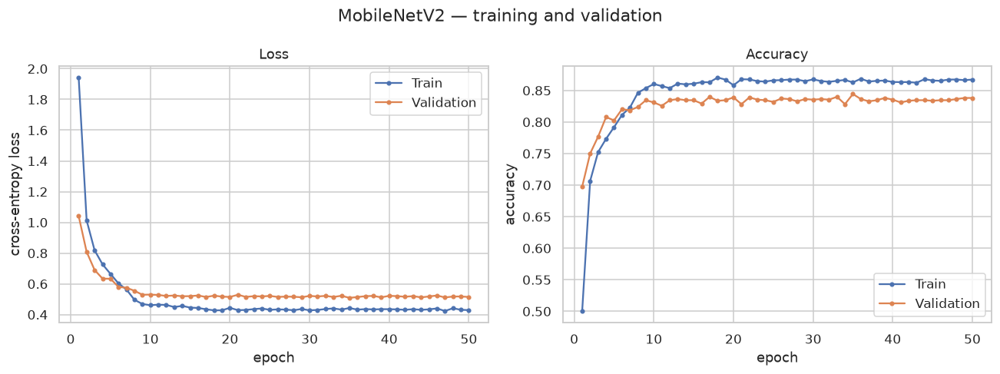

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec
45,46,0.439839,0.865201,0.524104,0.834520,1.000000e-09,45.933743
46,47,0.423261,0.867200,0.511568,0.834520,1.000000e-09,45.920407
47,48,0.441246,0.867311,0.517395,0.836299,1.000000e-09,46.314390
48,49,0.431148,0.866311,0.517918,0.838078,1.000000e-10,46.164687
49,50,0.429014,0.867200,0.514584,0.838078,1.000000e-10,45.703151


In [15]:
def plot_training_curves(history, title: str, output_path: Path):
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", ms=3, label="Train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", ms=3, label="Validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_title("Loss")
    axes[0].legend()

    axes[1].plot(frame["epoch"], frame["train_acc"], marker="o", ms=3, label="Train")
    axes[1].plot(frame["epoch"], frame["val_acc"], marker="o", ms=3, label="Validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].set_title("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_training_curves(
    mobilenet_history,
    "MobileNetV2 — training and validation",
    FIGURE_DIR / "mobilenetv2_curves.png",
)
display(pd.DataFrame(mobilenet_history).tail())

## 10. Evaluasi test: 30 kelas dan 3 superclass

Evaluasi utama mengikuti `test_model.py`: 30-class accuracy dan cross-entropy loss, lalu
`classification_report` untuk 3 superclass. Superclass diambil dari top-1 fine class melalui
`CLASS_TO_MAJOR`, sama seperti GitHub mengambil prefix `Major_minor`.

Metrik lain seperti top-3 accuracy, macro F1, akurasi per source group, probabilitas softmax per
superclass, dan confusion matrix disimpan sebagai insight tambahan. Metrik tersebut tidak mengubah
hasil evaluasi utama.


In [16]:
def jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, Path):
        return str(obj)
    return obj


def aggregate_major_probs(probs: np.ndarray, class_names):
    major_probs = np.zeros((probs.shape[0], len(MAJOR_NAMES)), dtype=np.float64)
    for class_idx, class_name in enumerate(class_names):
        major_probs[:, MAJOR_TO_IDX[CLASS_TO_MAJOR[class_name]]] += probs[:, class_idx]
    return major_probs


@torch.no_grad()
def predict_loader(model, loader, criterion, device):
    model.eval()
    all_probs, all_labels = [], []
    total_loss = 0.0
    total_samples = 0

    for images, labels in tqdm(loader, desc="Evaluating", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    if total_samples == 0:
        raise RuntimeError("Empty evaluation loader.")
    probs = np.concatenate(all_probs, axis=0)
    labels = np.concatenate(all_labels, axis=0)
    return probs, labels, total_loss / total_samples


def plot_confusion_matrix(cm, labels, title, output_path, normalize=True):
    cm = np.asarray(cm, dtype=np.float64)
    if normalize:
        row_sums = cm.sum(axis=1, keepdims=True)
        plot_cm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0)
        fmt = ".2f"
    else:
        plot_cm = cm
        fmt = "d"

    annot = len(labels) <= 12
    fig, ax = plt.subplots(figsize=(max(7, len(labels) * 0.48), max(6, len(labels) * 0.42)))
    sns.heatmap(
        plot_cm,
        annot=annot,
        fmt=fmt,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        cbar=True,
        linewidths=0.2 if annot else 0,
        annot_kws={"fontsize": 9} if annot else None,
    )
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def evaluate_and_save(model, loader, criterion, device, frame, model_key):
    probs, labels, loss = predict_loader(model, loader, criterion, device)
    preds = probs.argmax(axis=1)

    report_dict = classification_report(
        labels,
        preds,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(labels, preds, labels=np.arange(NUM_CLASSES))
    per_class_acc = np.divide(
        cm.diagonal(),
        cm.sum(axis=1),
        out=np.zeros(NUM_CLASSES, dtype=np.float64),
        where=cm.sum(axis=1) != 0,
    )

    major_probs = aggregate_major_probs(probs, CLASS_NAMES)
    major_true = frame["class_name"].map(lambda c: MAJOR_TO_IDX[CLASS_TO_MAJOR[c]]).to_numpy()
    # GitHub-style: map the top-1 fine class to its superclass.
    major_pred = np.array([
        MAJOR_TO_IDX[CLASS_TO_MAJOR[CLASS_NAMES[int(index)]]] for index in preds
    ])
    # Secondary metric: sum fine-class probabilities per superclass.
    major_prob_pred = major_probs.argmax(axis=1)
    major_report = classification_report(
        major_true,
        major_pred,
        labels=np.arange(len(MAJOR_NAMES)),
        target_names=MAJOR_NAMES,
        output_dict=True,
        zero_division=0,
    )
    major_cm = confusion_matrix(major_true, major_pred, labels=np.arange(len(MAJOR_NAMES)))

    prediction_frame = frame[["rel_path", "class_name", "source_group"]].copy()
    prediction_frame["true_label"] = labels
    prediction_frame["pred_label"] = preds
    prediction_frame["pred_class"] = [CLASS_NAMES[i] for i in preds]
    prediction_frame["confidence"] = probs.max(axis=1)
    prediction_frame["correct"] = (labels == preds).astype(int)
    for class_idx, class_name in enumerate(CLASS_NAMES):
        prediction_frame[f"prob_{class_name}"] = probs[:, class_idx]
    prediction_frame.to_csv(RESULT_DIR / f"{model_key}_predictions.csv", index=False)

    metrics = {
        "model": model_key,
        "split": "test",
        "num_test": int(len(labels)),
        "accuracy": float(accuracy_score(labels, preds)),
        "loss": float(loss),
        "top3_accuracy": float(
            top_k_accuracy_score(
                labels,
                probs,
                k=min(3, NUM_CLASSES),
                labels=np.arange(NUM_CLASSES),
            )
        ),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class_accuracy": {
            name: float(per_class_acc[i]) for i, name in enumerate(CLASS_NAMES)
        },
        "group_accuracy": {
            str(group): float(sub["correct"].mean())
            for group, sub in prediction_frame.groupby("source_group")
        },
        "classification_report": report_dict,
        "confusion_matrix": cm.tolist(),
        "major_accuracy": float(accuracy_score(major_true, major_pred)),
        "major_prob_accuracy": float(accuracy_score(major_true, major_prob_pred)),
        "major_report": major_report,
        "major_confusion_matrix": major_cm.tolist(),
        "major_class_names": MAJOR_NAMES,
        "class_names": CLASS_NAMES,
    }
    with open(RESULT_DIR / f"{model_key}_metrics.json", "w") as handle:
        json.dump(jsonable(metrics), handle, indent=2)

    pd.DataFrame(report_dict).T.to_csv(RESULT_DIR / f"{model_key}_classification_report.csv")
    pd.DataFrame(major_report).T.to_csv(
        RESULT_DIR / f"{model_key}_superclass_report.csv"
    )
    pd.DataFrame(
        per_class_acc, index=CLASS_NAMES, columns=["accuracy"]
    ).to_csv(RESULT_DIR / f"{model_key}_per_class_accuracy.csv")

    print(f"\n{model_key} — GitHub-style test results")
    print(f"  loss              : {metrics['loss']:.4f}")
    print(f"  30-class accuracy : {metrics['accuracy'] * 100:.2f}%")
    print("  superclass report : classification_report 3 superclass")
    print("\n  Insight tambahan:")
    print(f"  top-3 accuracy    : {metrics['top3_accuracy'] * 100:.2f}%")
    print(f"  3-class accuracy  : {metrics['major_accuracy'] * 100:.2f}% (top-1 prefix)")
    print(f"  3-class prob agg  : {metrics['major_prob_accuracy'] * 100:.2f}%")
    print(f"  macro F1          : {metrics['macro_f1']:.4f}")
    print("  accuracy by source group:")
    for group, value in metrics["group_accuracy"].items():
        print(f"    {group:10s}: {value * 100:.2f}%")

    return metrics, probs, labels, preds, major_true, major_pred

In [17]:
mobilenet_model, mobilenet_ckpt = None, None
mobilenet_model = build_mobilenet_v2(NUM_CLASSES, pretrained=False).to(DEVICE)
mobilenet_ckpt = load_checkpoint(MOBILENET_CHECKPOINT, DEVICE)
mobilenet_model.load_state_dict(mobilenet_ckpt["state_dict"])
mobilenet_model.eval()
print(
    f"Loaded checkpoint from epoch {mobilenet_ckpt['epoch']} "
    f"(val acc {mobilenet_ckpt['val_acc']:.4f})"
)

(
    mobilenet_metrics,
    mobilenet_test_probs,
    mobilenet_test_labels,
    mobilenet_test_preds,
    mobilenet_major_true,
    mobilenet_major_pred,
) = evaluate_and_save(
    mobilenet_model,
    test_loader,
    criterion,
    DEVICE,
    test_df,
    model_key="mobilenetv2",
)

print("GitHub-style evaluation: 30-class accuracy/loss dan classification report 3 superclass")
display(pd.DataFrame(mobilenet_metrics["major_report"]).T.round(3))
print("Insight tambahan: classification report 30 kelas")
display(pd.DataFrame(mobilenet_metrics["classification_report"]).T)

Loaded checkpoint from epoch 35 (val acc 0.8443)


Evaluating:   0%|                                                                                                                                                   | 0/9 [00:00<?, ?it/s]

Evaluating:  11%|███████████████▍                                                                                                                           | 1/9 [00:00<00:03,  2.35it/s]

Evaluating:  22%|██████████████████████████████▉                                                                                                            | 2/9 [00:00<00:03,  2.23it/s]

Evaluating:  33%|██████████████████████████████████████████████▎                                                                                            | 3/9 [00:01<00:02,  2.47it/s]

...

Evaluating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:03<00:00,  3.03it/s]


mobilenetv2 — GitHub-style test results
  loss              : 0.4653
  30-class accuracy : 85.17%
  superclass report : classification_report 3 superclass

  Insight tambahan:
  top-3 accuracy    : 96.12%
  3-class accuracy  : 96.20% (top-1 prefix)
  3-class prob agg  : 96.56%
  macro F1          : 0.8441
  accuracy by source group:
    default   : 87.96%
    real_world: 80.56%
GitHub-style evaluation: 30-class accuracy/loss dan classification report 3 superclass


,precision,recall,f1-score,support
Kitchen waste,0.944,0.925,0.935,147.000
Recyclable waste,0.979,0.970,0.974,767.000
Other waste,0.917,0.959,0.938,219.000
accuracy,0.962,0.962,0.962,0.962
macro avg,0.947,0.951,0.949,1133.000
weighted avg,0.963,0.962,0.962,1133.000


Insight tambahan: classification report 30 kelas


,precision,recall,f1-score,support
aerosol_cans,0.871795,0.944444,0.906667,36.000000
aluminum_food_cans,0.595238,0.641026,0.617284,39.000000
aluminum_soda_cans,0.767442,0.868421,0.814815,38.000000
cardboard_boxes,0.708333,0.871795,0.781609,39.000000
cardboard_packaging,0.727273,0.592593,0.653061,27.000000
clothing,0.860000,0.877551,0.868687,49.000000
coffee_grounds,0.971429,0.918919,0.944444,37.000000
disposable_plastic_cutlery,0.944444,0.944444,0.944444,36.000000
eggshells,0.948718,0.925000,0.936709,40.000000
food_waste,0.964286,0.900000,0.931034,30.000000


In [18]:
mobilenet_insights = pd.DataFrame({
    "Metric": [
        "top-3 accuracy",
        "3-class accuracy (top-1 prefix)",
        "3-class accuracy (probability aggregation)",
        "macro F1",
    ],
    "Value": [
        mobilenet_metrics["top3_accuracy"],
        mobilenet_metrics["major_accuracy"],
        mobilenet_metrics["major_prob_accuracy"],
        mobilenet_metrics["macro_f1"],
    ],
})
print("Insight tambahan: metrik MobileNetV2 di luar evaluasi GitHub")
display(mobilenet_insights.round(4))


Insight tambahan: metrik MobileNetV2 di luar evaluasi GitHub


,Metric,Value
0,top-3 accuracy,0.9612
1,3-class accuracy (top-1 prefix),0.9620
2,3-class accuracy (probability aggregation),0.9656
3,macro F1,0.8441


## 11. Confusion matrix

Matriks 30×30 dinormalisasi per kelas sebenarnya (setiap baris berjumlah 1). Matriks 3×3
memperlihatkan di mana model tertukar antara kitchen, recyclable, dan other waste. GitHub tidak
melaporkan confusion matrix; bagian ini hanya insight tambahan.


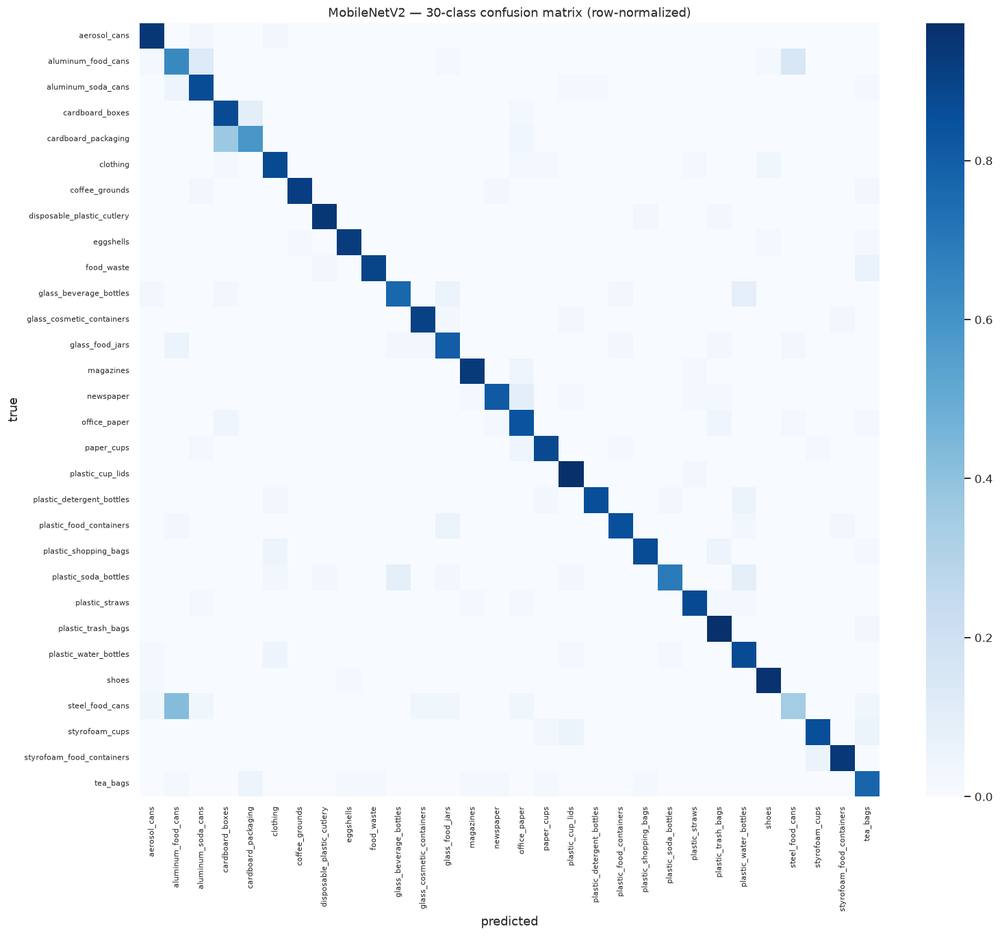

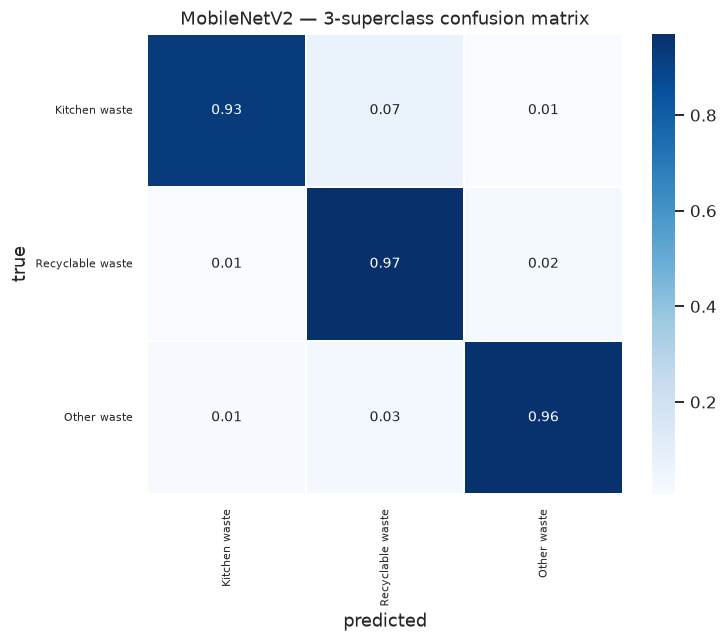

In [19]:
plot_confusion_matrix(
    np.array(mobilenet_metrics["confusion_matrix"]),
    CLASS_NAMES,
    "MobileNetV2 — 30-class confusion matrix (row-normalized)",
    FIGURE_DIR / "mobilenetv2_confusion_30.png",
    normalize=True,
)

plot_confusion_matrix(
    np.array(mobilenet_metrics["major_confusion_matrix"]),
    MAJOR_NAMES,
    "MobileNetV2 — 3-superclass confusion matrix",
    FIGURE_DIR / "mobilenetv2_confusion_major.png",
    normalize=True,
)

## 12. Inference tiga gambar

Menampilkan tiga gambar test sebagai contoh prediksi. Setiap panel memuat label sebenarnya,
prediksi top-1, dan dua prediksi berikutnya. Bagian ini hanya demonstrasi kualitatif dan tidak
menambah metrik evaluasi.

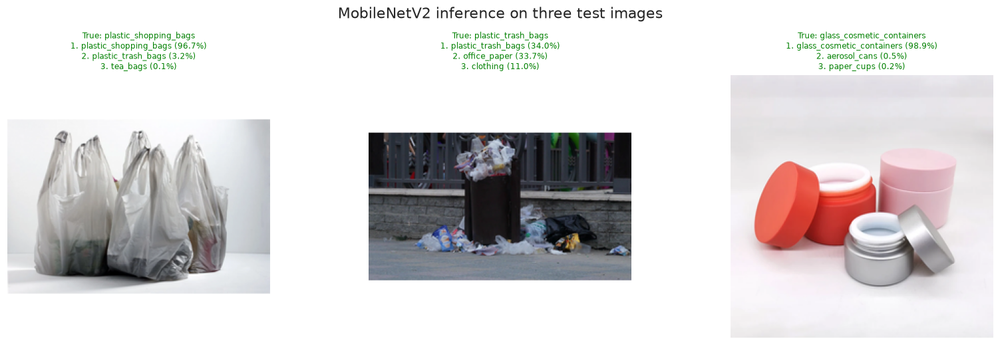

,rel_path,true_class,pred_class,confidence,correct,top5
0,plastic_shopping_bags/default/Image_82.png,plastic_shopping_bags,plastic_shopping_bags,0.9667,True,"plastic_shopping_bags (0.967), plastic_trash_b..."
1,plastic_trash_bags/real_world/Image_197.png,plastic_trash_bags,plastic_trash_bags,0.3403,True,"plastic_trash_bags (0.340), office_paper (0.33..."
2,glass_cosmetic_containers/default/Image_176.png,glass_cosmetic_containers,glass_cosmetic_containers,0.9888,True,"glass_cosmetic_containers (0.989), aerosol_can..."


In [20]:
@torch.no_grad()
def predict_single_image(image, model, class_names, transform, device, topk=5):
    if isinstance(image, (str, Path)):
        with Image.open(image) as img:
            image = img.convert("RGB")
    elif isinstance(image, Image.Image):
        image = image.convert("RGB")
    else:
        raise TypeError("image must be a path or a PIL.Image")

    tensor = transform(image).unsqueeze(0).to(device)
    probs = torch.softmax(model(tensor), dim=1)[0].cpu().numpy()
    order = np.argsort(probs)[::-1][:topk]
    return [(class_names[i], float(probs[i])) for i in order], image


sample_rows = test_df.sample(min(3, len(test_df)), random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(1, len(sample_rows), figsize=(5 * len(sample_rows), 4.8))
axes = np.atleast_1d(axes)

inference_rows = []
for ax, row in zip(axes, sample_rows.itertuples()):
    top_predictions, image = predict_single_image(
        DATA_ROOT / row.rel_path,
        mobilenet_model,
        CLASS_NAMES,
        eval_transform,
        DEVICE,
        topk=5,
    )
    top_name, top_prob = top_predictions[0]
    correct = top_name == row.class_name
    inference_rows.append({
        "rel_path": row.rel_path,
        "true_class": row.class_name,
        "pred_class": top_name,
        "confidence": top_prob,
        "correct": correct,
        "top5": ", ".join(f"{name} ({prob:.3f})" for name, prob in top_predictions),
    })

    top3_text = "\n".join(
        f"{rank}. {name} ({prob * 100:.1f}%)"
        for rank, (name, prob) in enumerate(top_predictions[:3], start=1)
    )
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(
        f"True: {row.class_name}\n{top3_text}",
        fontsize=8,
        color="green" if correct else "darkred",
    )

fig.suptitle("MobileNetV2 inference on three test images")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mobilenetv2_inference_examples.png", bbox_inches="tight")
plt.show()
plt.close(fig)

display(pd.DataFrame(inference_rows).round({"confidence": 4}))

## 13. CNN baseline

Mereproduksi model pembanding dari `train_cnn.py` dengan arsitektur yang sama:

```text
Rescaling(1/255) → Conv2D(32, 3×3, ReLU) → MaxPool(2×2)
                → Conv2D(64, 3×3, ReLU) → MaxPool(2×2)
                → Flatten → Dense(128, ReLU) → Dense(30, Softmax)
```

Kode asli memakai TensorFlow/Keras. Implementasi PyTorch di bawah mempertahankan bentuk layer,
optimizer (Adam, 30 epoch), dan preprocessing: `Resize((224, 224))` lalu `ToTensor()` (0–1,
ekuivalen dengan `Rescaling(1/255)`), tanpa augmentasi dan tanpa normalisasi ImageNet. Batch size
16, sama seperti `train_cnn.py`. CNN memakai transform terpisah agar pipeline MobileNetV2 tidak
tercampur ke model pembanding.


In [21]:
class ClassicalCNN(nn.Module):
    '''Two-convolution CNN matching the paper's comparison model.'''

    def __init__(self, num_classes: int, in_shape=(3, 224, 224)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        with torch.no_grad():
            flat_features = self.features(torch.zeros(1, *in_shape)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_model = ClassicalCNN(NUM_CLASSES, in_shape=(3, IMG_SIZE, IMG_SIZE)).to(DEVICE)
print(cnn_model)
print(f"Trainable parameters: {count_parameters(cnn_model):,}")

cnn_train_loader = make_loader(
    train_df,
    training=True,
    batch_size=CNN_BATCH_SIZE,
    transform=cnn_transform,
)
cnn_val_loader = make_loader(
    val_df,
    training=False,
    batch_size=CNN_BATCH_SIZE,
    transform=cnn_transform,
)
cnn_test_loader = make_loader(
    test_df,
    training=False,
    batch_size=TEST_BATCH_SIZE,
    transform=cnn_transform,
)

cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=CNN_LEARNING_RATE)

ClassicalCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=186624, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=128, out_features=30, bias=True)
  )
)
Trainable parameters: 23,911,262


Epoch 1/30
----------


CNN train 1/30:   0%|                                                                                                                                            | 0/9006 [00:00<?, ?it/s]

CNN train 1/30:   0%|▏                                                                                                                                  | 16/9006 [00:00<03:47, 39.57it/s]

CNN train 1/30:   1%|▋                                                                                                                                 | 48/9006 [00:00<01:26, 103.55it/s]

CNN train 1/30:   1%|█▏                                                                                                                                | 80/9006 [00:00<01:01, 144.16it/s]

...

CNN val 30/30:  90%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋             | 1008/1124 [00:02<00:00, 372.17it/s]

CNN val 30/30:  94%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏       | 1056/1124 [00:02<00:00, 372.58it/s]

CNN val 30/30:  98%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▋  | 1104/1124 [00:03<00:00, 369.15it/s]

val Loss: 7.1434 Acc: 0.4075
[CNN] epoch 30/30 | train loss 0.0979 acc 0.9748 | val loss 7.1434 acc 0.4075 | lr 1.00e-03 | 36.0s

Training complete in 18m 1s
Best val Acc: 0.4270 at epoch 9


Full model: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/cnn_baseline_trash30_full.pt
Checkpoint: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/cnn_baseline_trash30_best.pt


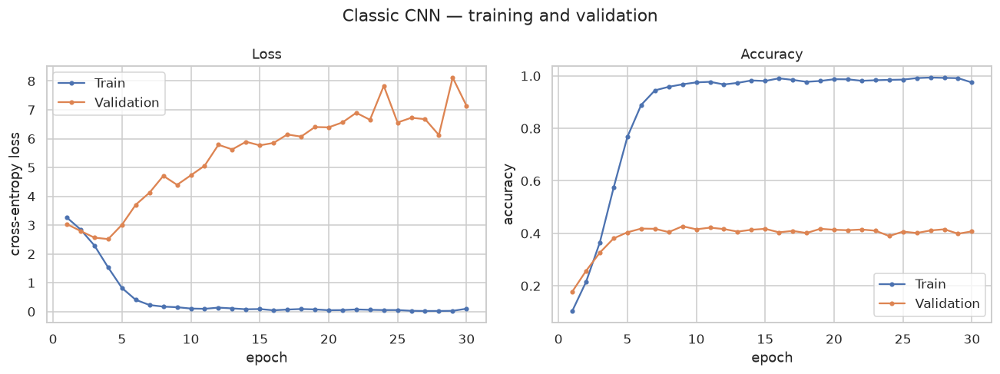

In [22]:
CNN_CHECKPOINT = MODEL_DIR / "cnn_baseline_trash30_best.pt"
CNN_FULL_MODEL = MODEL_DIR / "cnn_baseline_trash30_full.pt"
CNN_HISTORY = RESULT_DIR / "cnn_baseline_history.csv"

cnn_history, cnn_best_val_acc = train_model(
    model=cnn_model,
    train_loader=cnn_train_loader,
    val_loader=cnn_val_loader,
    criterion=cnn_criterion,
    optimizer=cnn_optimizer,
    scheduler=None,
    epochs=CNN_EPOCHS,
    device=DEVICE,
    checkpoint_path=CNN_CHECKPOINT,
    full_model_path=CNN_FULL_MODEL,
    history_path=CNN_HISTORY,
    model_name="CNN",
    arch="classical_cnn",
    extra_config={"learning_rate": CNN_LEARNING_RATE, "batch_size": CNN_BATCH_SIZE},
)

plot_training_curves(
    cnn_history,
    "Classic CNN — training and validation",
    FIGURE_DIR / "cnn_curves.png",
)

In [23]:
cnn_model_best = ClassicalCNN(NUM_CLASSES, in_shape=(3, IMG_SIZE, IMG_SIZE)).to(DEVICE)
cnn_ckpt = load_checkpoint(CNN_CHECKPOINT, DEVICE)
cnn_model_best.load_state_dict(cnn_ckpt["state_dict"])
cnn_model_best.eval()
print(f"Loaded CNN checkpoint from epoch {cnn_ckpt['epoch']} "
      f"(val acc {cnn_ckpt['val_acc']:.4f})")

(
    cnn_metrics,
    cnn_test_probs,
    cnn_test_labels,
    cnn_test_preds,
    cnn_major_true,
    cnn_major_pred,
) = evaluate_and_save(
    cnn_model_best,
    cnn_test_loader,
    cnn_criterion,
    DEVICE,
    test_df,
    model_key="cnn_baseline",
)

print("GitHub-style evaluation: 30-class accuracy/loss dan classification report 3 superclass")
display(pd.DataFrame(cnn_metrics["major_report"]).T.round(3))
print("Insight tambahan: classification report 30 kelas")
display(pd.DataFrame(cnn_metrics["classification_report"]).T)

Loaded CNN checkpoint from epoch 9 (val acc 0.4270)


Evaluating:   0%|                                                                                                                                                   | 0/9 [00:00<?, ?it/s]

Evaluating:  11%|███████████████▍                                                                                                                           | 1/9 [00:00<00:03,  2.48it/s]

Evaluating:  22%|██████████████████████████████▉                                                                                                            | 2/9 [00:00<00:02,  2.68it/s]

Evaluating:  33%|██████████████████████████████████████████████▎                                                                                            | 3/9 [00:01<00:02,  2.55it/s]

...

Evaluating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:03<00:00,  2.64it/s]


cnn_baseline — GitHub-style test results
  loss              : 4.3413
  30-class accuracy : 40.07%
  superclass report : classification_report 3 superclass

  Insight tambahan:
  top-3 accuracy    : 56.66%
  3-class accuracy  : 72.02% (top-1 prefix)
  3-class prob agg  : 73.79%
  macro F1          : 0.3923
  accuracy by source group:
    default   : 43.48%
    real_world: 34.43%
GitHub-style evaluation: 30-class accuracy/loss dan classification report 3 superclass


,precision,recall,f1-score,support
Kitchen waste,0.543,0.599,0.570,147.00
Recyclable waste,0.841,0.763,0.800,767.00
Other waste,0.520,0.653,0.579,219.00
accuracy,0.720,0.720,0.720,0.72
macro avg,0.635,0.671,0.649,1133.00
weighted avg,0.740,0.720,0.727,1133.00


Insight tambahan: classification report 30 kelas


,precision,recall,f1-score,support
aerosol_cans,0.583333,0.388889,0.466667,36.000000
aluminum_food_cans,0.425000,0.435897,0.430380,39.000000
aluminum_soda_cans,0.500000,0.368421,0.424242,38.000000
cardboard_boxes,0.444444,0.410256,0.426667,39.000000
cardboard_packaging,0.461538,0.222222,0.300000,27.000000
clothing,0.361111,0.530612,0.429752,49.000000
coffee_grounds,0.821429,0.621622,0.707692,37.000000
disposable_plastic_cutlery,0.294118,0.416667,0.344828,36.000000
eggshells,0.425532,0.500000,0.459770,40.000000
food_waste,0.377778,0.566667,0.453333,30.000000


Insight tambahan: metrik CNN di luar evaluasi GitHub


,Metric,Value
0,top-3 accuracy,0.5666
1,3-class accuracy (top-1 prefix),0.7202
2,3-class accuracy (probability aggregation),0.7379
3,macro F1,0.3923


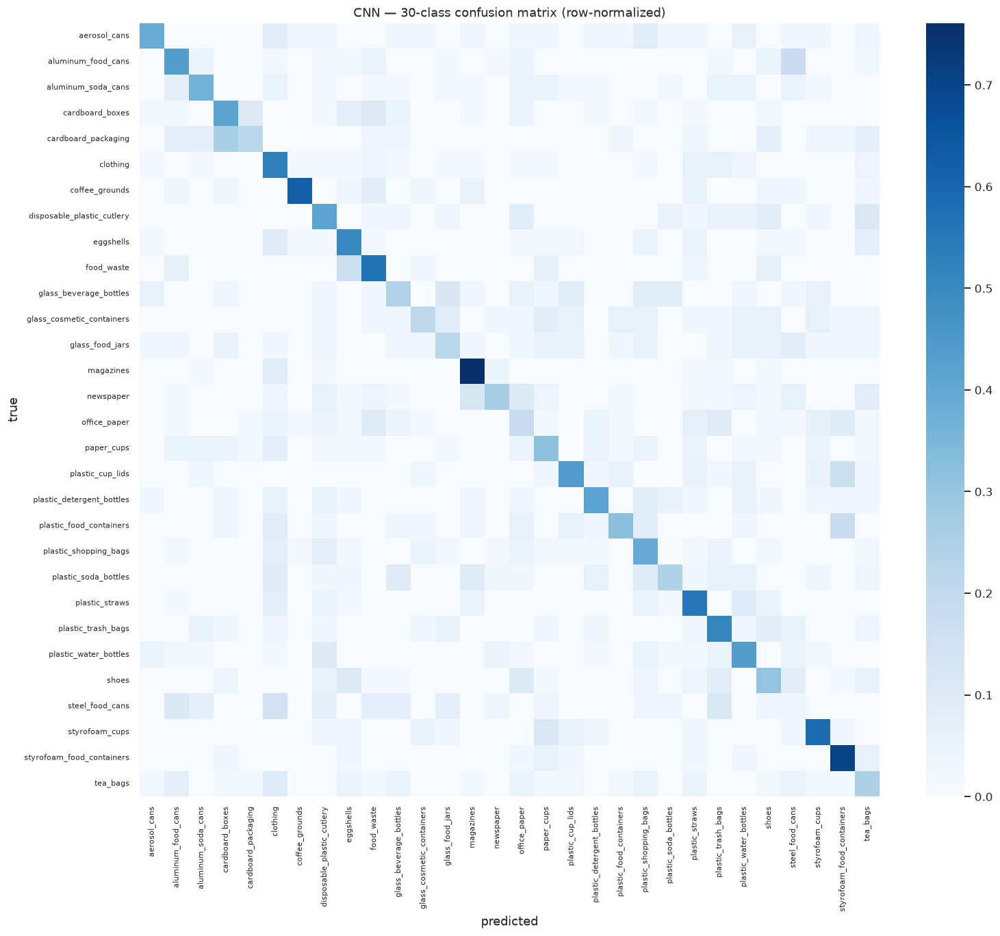

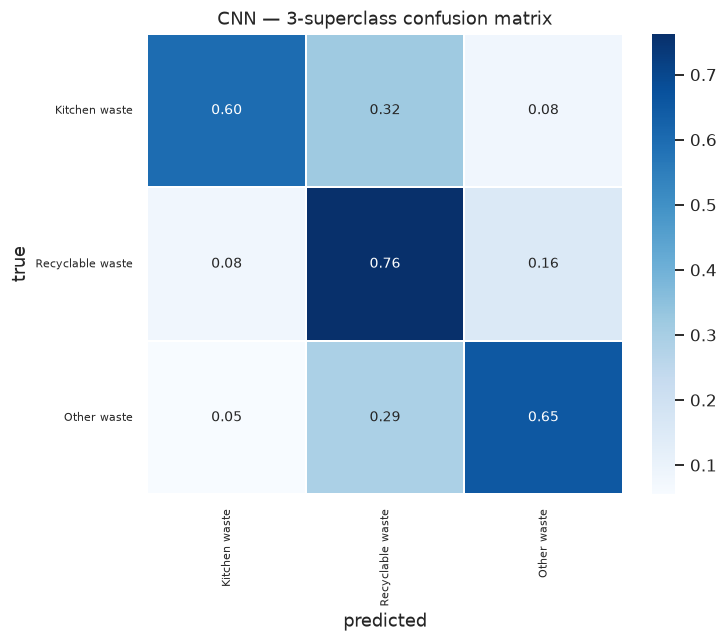

In [24]:
print("Insight tambahan: metrik CNN di luar evaluasi GitHub")
display(pd.DataFrame({
    "Metric": [
        "top-3 accuracy",
        "3-class accuracy (top-1 prefix)",
        "3-class accuracy (probability aggregation)",
        "macro F1",
    ],
    "Value": [
        cnn_metrics["top3_accuracy"],
        cnn_metrics["major_accuracy"],
        cnn_metrics["major_prob_accuracy"],
        cnn_metrics["macro_f1"],
    ],
}).round(4))

plot_confusion_matrix(
    np.array(cnn_metrics["confusion_matrix"]),
    CLASS_NAMES,
    "CNN — 30-class confusion matrix (row-normalized)",
    FIGURE_DIR / "cnn_confusion_30.png",
    normalize=True,
)

plot_confusion_matrix(
    np.array(cnn_metrics["major_confusion_matrix"]),
    MAJOR_NAMES,
    "CNN — 3-superclass confusion matrix",
    FIGURE_DIR / "cnn_confusion_major.png",
    normalize=True,
)

## 14. Analisis kesalahan testing

Bagian ini menampilkan contoh gambar test yang salah diprediksi, pasangan kelas yang paling sering
tertukar, dan prediksi yang seharusnya. Analisis ini tidak mengubah metrik; tujuannya melihat pola
error pada kedua model.

MobileNetV2: 168 salah dari 1,133 gambar test


,rel_path,true_class,pred_class,confidence
0,paper_cups/real_world/Image_23.png,paper_cups,styrofoam_cups,0.997400
1,plastic_soda_bottles/real_world/Image_164.png,plastic_soda_bottles,glass_beverage_bottles,0.989071
2,plastic_food_containers/real_world/Image_123.png,plastic_food_containers,styrofoam_food_containers,0.981355
3,styrofoam_cups/real_world/Image_61.png,styrofoam_cups,paper_cups,0.976451
4,cardboard_packaging/default/Image_186.png,cardboard_packaging,cardboard_boxes,0.972817
5,aluminum_food_cans/default/Image_33.png,aluminum_food_cans,aluminum_soda_cans,0.966372
6,newspaper/real_world/Image_115.png,newspaper,office_paper,0.959498
7,eggshells/default/Image_167.png,eggshells,coffee_grounds,0.946423
8,cardboard_packaging/default/Image_39.png,cardboard_packaging,office_paper,0.935594
9,food_waste/default/Image_126.png,food_waste,tea_bags,0.928775


Pasangan kelas yang paling sering tertukar:


,true_class,pred_class,count
0,steel_food_cans,aluminum_food_cans,11
1,cardboard_packaging,cardboard_boxes,10
2,aluminum_food_cans,steel_food_cans,6
3,newspaper,office_paper,5
4,aluminum_food_cans,aluminum_soda_cans,5
5,cardboard_boxes,cardboard_packaging,4
6,plastic_soda_bottles,plastic_water_bottles,3
7,plastic_soda_bottles,glass_beverage_bottles,3
8,glass_beverage_bottles,plastic_water_bottles,3
9,clothing,shoes,2


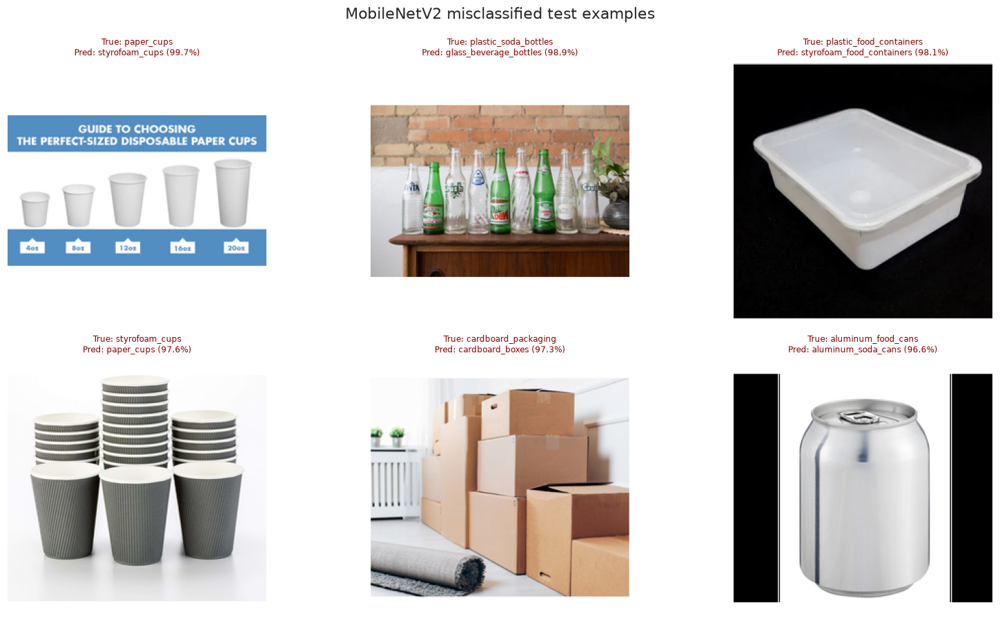

CNN: 679 salah dari 1,133 gambar test


,rel_path,true_class,pred_class,confidence
0,newspaper/real_world/Image_169.png,newspaper,magazines,1.000000
1,aluminum_soda_cans/default/Image_85.png,aluminum_soda_cans,plastic_cup_lids,1.000000
2,aluminum_soda_cans/real_world/Image_122.png,aluminum_soda_cans,magazines,0.999999
3,newspaper/real_world/Image_64.png,newspaper,plastic_food_containers,0.999998
4,newspaper/real_world/Image_208.png,newspaper,magazines,0.999997
5,paper_cups/default/Image_87.png,paper_cups,plastic_straws,0.999995
6,newspaper/real_world/Image_175.png,newspaper,paper_cups,0.999990
7,plastic_shopping_bags/default/Image_176.png,plastic_shopping_bags,plastic_trash_bags,0.999986
8,plastic_water_bottles/default/Image_205.png,plastic_water_bottles,disposable_plastic_cutlery,0.999975
9,eggshells/real_world/Image_159.png,eggshells,shoes,0.999960


Pasangan kelas yang paling sering tertukar:


,true_class,pred_class,count
0,aluminum_food_cans,steel_food_cans,7
1,cardboard_packaging,cardboard_boxes,7
2,plastic_cup_lids,styrofoam_food_containers,6
3,plastic_food_containers,styrofoam_food_containers,6
4,newspaper,magazines,6
5,shoes,eggshells,5
6,newspaper,office_paper,5
7,food_waste,eggshells,5
8,shoes,office_paper,5
9,cardboard_boxes,cardboard_packaging,4


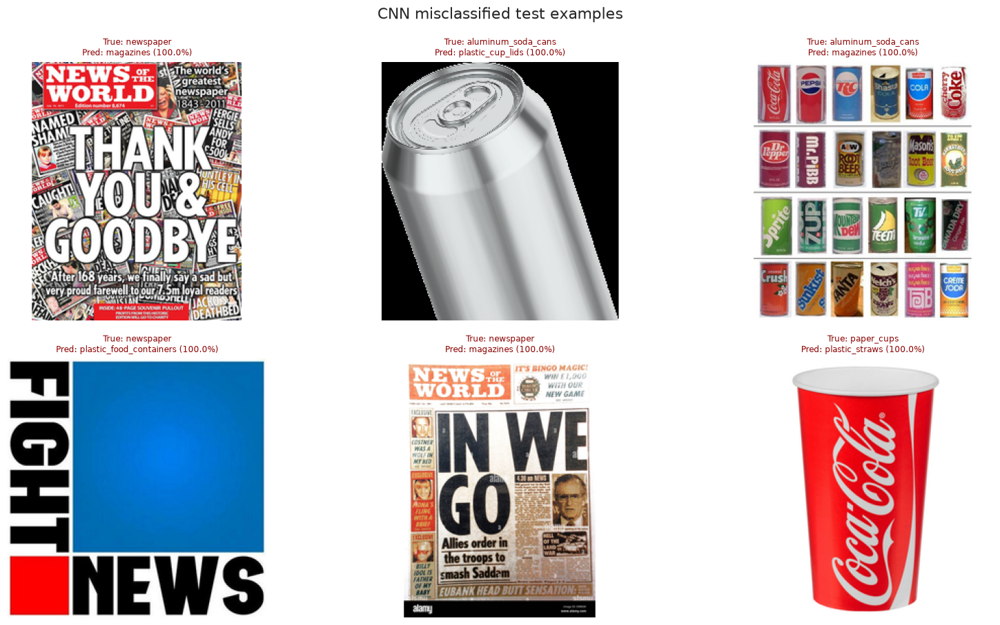

In [25]:
def build_prediction_frame(frame, probs, labels, preds):
    result = frame[["rel_path", "class_name", "source_group"]].copy()
    result["true_class"] = [CLASS_NAMES[int(i)] for i in labels]
    result["pred_class"] = [CLASS_NAMES[int(i)] for i in preds]
    result["confidence"] = probs.max(axis=1)
    result["correct"] = result["true_class"].eq(result["pred_class"])
    return result


def show_misclassified(predictions, model_name, output_path, max_examples=6):
    errors = (
        predictions[~predictions["correct"]]
        .sort_values("confidence", ascending=False)
        .reset_index(drop=True)
    )
    print(f"{model_name}: {len(errors):,} salah dari {len(predictions):,} gambar test")
    if errors.empty:
        print("Tidak ada gambar yang salah diprediksi.")
        return errors

    display(errors[["rel_path", "true_class", "pred_class", "confidence"]].head(12))

    pair_counts = (
        errors.groupby(["true_class", "pred_class"])
        .size()
        .sort_values(ascending=False)
        .head(10)
        .rename("count")
        .reset_index()
    )
    print("Pasangan kelas yang paling sering tertukar:")
    display(pair_counts)

    examples = errors.head(max_examples)
    ncols = min(3, len(examples))
    nrows = math.ceil(len(examples) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(DATA_ROOT / row["rel_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(
            f"True: {row['true_class']}\nPred: {row['pred_class']} ({row['confidence'] * 100:.1f}%)",
            fontsize=8,
            color="darkred",
        )
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    fig.suptitle(f"{model_name} misclassified test examples")
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    errors.to_csv(
        RESULT_DIR / f"{model_name.lower().replace(' ', '_')}_misclassified.csv",
        index=False,
    )
    return errors


mobilenet_predictions = build_prediction_frame(
    test_df, mobilenet_test_probs, mobilenet_test_labels, mobilenet_test_preds
)
cnn_predictions = build_prediction_frame(
    test_df, cnn_test_probs, cnn_test_labels, cnn_test_preds
)

mobilenet_errors = show_misclassified(
    mobilenet_predictions,
    "MobileNetV2",
    FIGURE_DIR / "mobilenetv2_misclassified_examples.png",
)
cnn_errors = show_misclassified(
    cnn_predictions,
    "CNN",
    FIGURE_DIR / "cnn_misclassified_examples.png",
)

## 15. Perbandingan model

Tabel utama mengikuti Table 1 paper dan evaluasi `test_model.py`: test accuracy, cross-entropy loss,
dan classification report per superclass (precision, recall, F1, support). Ini metrik pembanding
utama.

Paper melaporkan:

| Model | Accuracy | Cross-entropy loss |
|---|---:|---:|
| CNN | 67.50% | 4.075 |
| MobileNetV2 | 82.92% | 1.621 |

Nilai yang dicetak di bawah adalah hasil reproduksi pada dataset Kaggle dan wajar berbeda.
Perbandingan yang bermakna adalah selisih antara kedua model pada split data yang sama, dengan
preprocessing masing-masing mengikuti paper/GitHub, bukan jarak absolut terhadap angka paper.

Metrik lain seperti top-3 accuracy, macro F1, akurasi 3 superclass, dan jumlah parameter
ditampilkan pada bagian insight tambahan.


GitHub-style evaluation: accuracy, loss, dan classification report per superclass


,Test accuracy (%),Cross-entropy loss
Model,,
MobileNetV2,85.17,0.47
CNN,40.07,4.34


MobileNetV2 superclass metrics


,Category,precision,recall,f1-score,support
0,Kitchen waste,0.944,0.925,0.935,147
1,Recyclable waste,0.979,0.970,0.974,767
2,Other waste,0.917,0.959,0.938,219


CNN superclass metrics


,Category,precision,recall,f1-score,support
0,Kitchen waste,0.543,0.599,0.570,147
1,Recyclable waste,0.841,0.763,0.800,767
2,Other waste,0.520,0.653,0.579,219


Insight tambahan


,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1,Parameters (M)
Model,,,,,
MobileNetV2,96.117,96.205,96.558,0.844,2.262
CNN,56.664,72.021,73.786,0.392,23.911


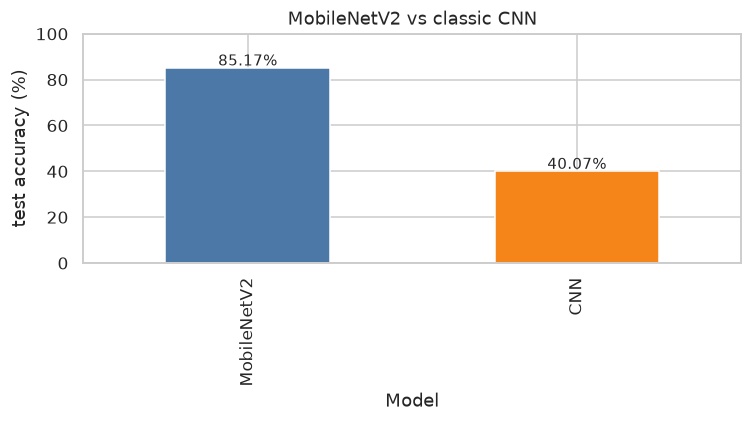

MobileNetV2 minus CNN: +45.10 percentage points


In [26]:
def major_table(metrics):
    rows = []
    for major_name in MAJOR_NAMES:
        row = metrics["major_report"][major_name]
        rows.append({
            "Category": major_name,
            "precision": row["precision"],
            "recall": row["recall"],
            "f1-score": row["f1-score"],
            "support": int(row["support"]),
        })
    return pd.DataFrame(rows)


comparison = pd.DataFrame([
    {
        "Model": "MobileNetV2",
        "Test accuracy (%)": mobilenet_metrics["accuracy"] * 100,
        "Cross-entropy loss": mobilenet_metrics["loss"],
    },
    {
        "Model": "CNN",
        "Test accuracy (%)": cnn_metrics["accuracy"] * 100,
        "Cross-entropy loss": cnn_metrics["loss"],
    },
]).set_index("Model")

comparison.to_csv(RESULT_DIR / "model_comparison.csv")
print("GitHub-style evaluation: accuracy, loss, dan classification report per superclass")
display(comparison.round(2))

print("MobileNetV2 superclass metrics")
display(major_table(mobilenet_metrics).round(3))
print("CNN superclass metrics")
display(major_table(cnn_metrics).round(3))

insights = pd.DataFrame([
    {
        "Model": "MobileNetV2",
        "Top-3 accuracy (%)": mobilenet_metrics["top3_accuracy"] * 100,
        "3-class accuracy (%)": mobilenet_metrics["major_accuracy"] * 100,
        "3-class prob accuracy (%)": mobilenet_metrics["major_prob_accuracy"] * 100,
        "Macro F1": mobilenet_metrics["macro_f1"],
        "Parameters (M)": count_parameters(mobilenet_model) / 1e6,
    },
    {
        "Model": "CNN",
        "Top-3 accuracy (%)": cnn_metrics["top3_accuracy"] * 100,
        "3-class accuracy (%)": cnn_metrics["major_accuracy"] * 100,
        "3-class prob accuracy (%)": cnn_metrics["major_prob_accuracy"] * 100,
        "Macro F1": cnn_metrics["macro_f1"],
        "Parameters (M)": count_parameters(cnn_model_best) / 1e6,
    },
]).set_index("Model")

insights.to_csv(RESULT_DIR / "model_insights.csv")
print("Insight tambahan")
display(insights.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
comparison["Test accuracy (%)"].plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set_ylim(0, 100)
ax.set_ylabel("test accuracy (%)")
ax.set_title("MobileNetV2 vs classic CNN")
for i, value in enumerate(comparison["Test accuracy (%)"]):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", bbox_inches="tight")
plt.show()
plt.close(fig)

delta = mobilenet_metrics["accuracy"] * 100 - cnn_metrics["accuracy"] * 100
print(f"MobileNetV2 minus CNN: {delta:+.2f} percentage points")


## 16. Simpan ringkasan

Cell terakhir menulis ringkasan machine-readable (`outputs/results/summary.json`) yang berisi
informasi dataset, hyperparameter, metrik kedua model, dan versi library. Aplikasi tidak
diimplementasikan.


In [27]:
summary = {
    "paper": {
        "title": "Application of MobileNetV2 to waste classification",
        "authors": "Yong, Ma, Sun, Du",
        "journal": "PLOS ONE 18(3): e0282336",
        "doi": "10.1371/journal.pone.0282336",
    },
    "dataset": {
        "source": KAGGLE_DATASET_URL,
        "source_groups": sorted(df["source_group"].unique().tolist()),
        "deduplication": "md5",
        "duplicates_removed": int(duplicates_removed),
        "root": str(DATA_ROOT),
        "num_classes": NUM_CLASSES,
        "num_images": int(len(df)),
        "split_sizes": {
            split_name: int((df["split"] == split_name).sum())
            for split_name in ("train", "val", "test")
        },
        "class_names": CLASS_NAMES,
        "major_names": MAJOR_NAMES,
        "class_to_major": CLASS_TO_MAJOR,
    },
    "training": {
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "num_epochs": NUM_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM,
        "step_size": STEP_SIZE,
        "gamma": GAMMA,
        "cnn_batch_size": CNN_BATCH_SIZE,
        "cnn_epochs": CNN_EPOCHS,
        "test_batch_size": TEST_BATCH_SIZE,
        "seed": SEED,
        "device": str(DEVICE),
        "quick_test": QUICK_TEST,
    },
    "results": {
        "mobilenetv2": {
            "accuracy": mobilenet_metrics["accuracy"],
            "loss": mobilenet_metrics["loss"],
            "top3_accuracy": mobilenet_metrics["top3_accuracy"],
            "major_accuracy": mobilenet_metrics["major_accuracy"],
            "major_prob_accuracy": mobilenet_metrics["major_prob_accuracy"],
            "macro_f1": mobilenet_metrics["macro_f1"],
            "parameters": count_parameters(mobilenet_model),
        },
        "cnn": {
            "accuracy": cnn_metrics["accuracy"],
            "loss": cnn_metrics["loss"],
            "top3_accuracy": cnn_metrics["top3_accuracy"],
            "major_accuracy": cnn_metrics["major_accuracy"],
            "major_prob_accuracy": cnn_metrics["major_prob_accuracy"],
            "macro_f1": cnn_metrics["macro_f1"],
            "parameters": count_parameters(cnn_model_best),
        },
        "accuracy_delta_mobilenet_minus_cnn": (
            mobilenet_metrics["accuracy"] - cnn_metrics["accuracy"]
        ),
    },
    "artifacts": {
        "mobilenetv2_full_model": str(MOBILENET_FULL_MODEL),
        "mobilenetv2_checkpoint": str(MOBILENET_CHECKPOINT),
        "cnn_full_model": str(CNN_FULL_MODEL),
        "cnn_checkpoint": str(CNN_CHECKPOINT),
    },
    "versions": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "torchvision": __import__("torchvision").__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}
with open(RESULT_DIR / "summary.json", "w") as handle:
    json.dump(jsonable(summary), handle, indent=2)
print("Wrote", RESULT_DIR / "summary.json")

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(OUTPUT_DIR)}")

Wrote /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/results/summary.json

Output files:
  figures/class_distribution.png
  figures/class_samples.png
  figures/cnn_confusion_30.png
  figures/cnn_confusion_major.png
  figures/cnn_curves.png
  figures/cnn_misclassified_examples.png
  figures/eda_class_balance.png
  figures/eda_image_stats.png
  figures/mobilenetv2_confusion_30.png
  figures/mobilenetv2_confusion_major.png
  figures/mobilenetv2_curves.png
  figures/mobilenetv2_inference_examples.png
  figures/mobilenetv2_misclassified_examples.png
  figures/model_comparison.png
  models/cnn_baseline_trash30_best.pt
  models/cnn_baseline_trash30_full.pt
  models/mobilenetv2_trash30_best.pt
  models/mobilenetv2_trash30_full.pt
  results/cnn_baseline_classification_report.csv
  results/cnn_baseline_history.csv
  results/cnn_baseline_metrics.json
  results/cnn_baseline_per_class_accuracy.csv
  results/cnn_baseline_predictions.csv
  results/cnn_baseline_superclass_report.csv
  

## Perbedaan dengan paper dan Source Code

| Aspek | Paper / Source Code | Notebook |
|---|---|---|
| Dataset | Dataset asli 245 fine class, sekitar 80.000 gambar | Dataset Kaggle 30 fine class, 15.000 file dari `default` dan `real_world`, menjadi 11.263 gambar unik setelah dedupe |
| Superclass | 4 kategori: Kitchen waste, Recyclable waste, Hazardous waste, Other waste | 3 kategori: Kitchen waste, Recyclable waste, Other waste |
| Nama kelas | `Major_minor`, misalnya `Kitchen waste_apple` | `snake_case`, misalnya `food_waste` |
| Label superclass | Prefix sebelum `_` | Mapping manual `CLASS_TO_MAJOR` |
| Split | `utils.py` menyalin file 8:1:1 tanpa seed; `test_model.py` membagi ulang data | Manifest CSV 9.006 train, 1.124 validation, 1.133 test; stratified per kelas dan source group; seed 42 |
| Duplikasi | Tidak ada penanganan duplikat | MD5 dedupe sebelum split |
| Validation loader | `shuffle=True` | `shuffle=False` |
| Framework | PyTorch dan TensorFlow/Keras | PyTorch untuk MobileNetV2 dan CNN |
| Preprocessing CNN | `Rescaling(1/255)` dan resize 224 | `Resize((224, 224))` dan `ToTensor()` 0-1 |
| Checkpoint CNN | Model epoch terakhir | Checkpoint validation terbaik |
| Penyimpanan model | Full model `.pt`, `.pth`, `.pkl` | Full model `.pt` dan checkpoint `state_dict` berisi metadata |
| Evaluasi | Accuracy dan loss di paper; `classification_report` 4 superclass di GitHub | Accuracy, loss, dan `classification_report` 3 superclass; metrik lain sebagai insight tambahan |
| Aplikasi | Flask backend dan mobile app | Tidak diimplementasikan |

Paper tidak konsisten soal epoch MobileNetV2. Bagian Methods dan `train_245_class.py` memakai 50 epoch, sedangkan caption Fig 5 menyebut 30. Notebook memakai 50 epoch.

Seed 42, `torch.backends.cudnn.deterministic`, manifest split, dan metadata checkpoint dipakai agar hasil bisa dilacak dan split tidak berubah antar-run. Operasi GPU dan versi library masih bisa menghasilkan selisih kecil.


## Kendala dan solusi

1. Dataset asli tidak tersedia. Paper memakai sekitar 80.000 gambar, tetapi sumber yang ditemukan hanya berisi 477 gambar. Dataset Kaggle 30 kelas dengan 15.000 gambar dipakai sebagai pengganti agar training dan evaluasi tetap bisa dijalankan.

2. Dataset Kaggle banyak berisi gambar duplikat, termasuk duplikat antar kelas. Semua gambar di-hash dengan MD5 sebelum split. Duplikat dihapus dengan `drop_duplicates("md5", keep="first")`, lalu split diperiksa agar tidak ada MD5 yang sama di train, validation, dan test.

3. Dataset Kaggle tidak memiliki major class. `CLASS_TO_MAJOR` dibuat manual untuk memetakan 30 fine class ke `Kitchen waste`, `Recyclable waste`, dan `Other waste`.

4. TensorFlow gagal mendeteksi GPU pada server. Seluruh pipeline ditulis dengan PyTorch, termasuk CNN yang di GitHub memakai Keras. Arsitektur CNN tetap mengikuti paper: Conv 32, pool, Conv 64, pool, Dense 128, dan output.

5. Aplikasi mobile dari paper dan GitHub tidak diimplementasikan. Fokus reproduksi ada di computer vision.
